# Exploración de precios de venta en CABA

Avisos de casas, departamentos y PH en venta en Capital Federal, bajados de ZonaProp.
El objetivo de esta notebook es mirar el **precio publicado en USD** antes de modelarlo:
cómo se distribuye, qué lo acompaña y qué hay que limpiar.

El precio es el del aviso, no un precio de cierre. Varias columnas salen del texto de la
descripción (amenities, jardín, parrilla, pileta)
y entran en los mismos gráficos que el resto.

Orden de la lectura:

1. Armado de variables y reglas de valores imposibles
2. Valores faltantes
3. Percentiles y media
4. Distribuciones
5. Outliers
6. Precio contra otras variables
7. Correlograma
8. Mapa de valores por barrio
9. Mapa de calor con la red de subte


In [1]:
%matplotlib inline

import json
import unicodedata
import urllib.request
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.lines import Line2D
from matplotlib.path import Path as Poligono
from matplotlib.ticker import FuncFormatter
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from scipy.stats import gaussian_kde

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 9

COLOR = "#1f4e79"
ACENTO = "#c0392b"
VERDE = "#1b7f5a"

RAIZ = Path.cwd().resolve()
if not (RAIZ / "src" / "scrape.py").exists():
    for padre in RAIZ.parents:
        if (padre / "src" / "scrape.py").exists():
            RAIZ = padre
            break

DATOS = RAIZ / "data" / "casas-departamentos-ph-venta-capital-federal.csv"
GEO = RAIZ / "data" / "geo"
GEO.mkdir(parents=True, exist_ok=True)

ARCHIVOS_GEO = {
    "barrios.geojson": "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/barrios/barrios.geojson",
    "estaciones_de_subte.geojson": "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/subte-estaciones/estaciones_de_subte.geojson",
    "red_subte.geojson": "https://cdn.buenosaires.gob.ar/datosabiertos/datasets/sbase/subte-estaciones/red_subte.geojson",
}

NOMBRES = {
    "precio_usd": "Precio publicado (USD)",
    "precio_m2_usd": "Precio por m² (USD)",
    "superficie_total": "Superficie total (m²)",
    "superficie_cubierta": "Superficie cubierta (m²)",
    "superficie_descubierta": "Superficie descubierta (m²)",
    "ambientes": "Ambientes",
    "dormitorios": "Dormitorios",
    "banos": "Baños",
    "toilettes": "Toilettes",
    "cocheras": "Cocheras",
    "antiguedad": "Antigüedad (años)",
    "expensas": "Expensas (ARS)",
    "fotos": "Fotos del aviso",
    "distancia_subte_km": "Distancia al subte (km)",
    "amenities": "Amenities",
    "jardin": "Jardín",
    "parrilla": "Parrilla",
    "pileta": "Pileta o piscina",
    "tipo": "Tipo",
    "tipo_publicado": "Tipo publicado",
    "tipo_aviso": "Tipo de aviso",
    "disposicion": "Disposición",
    "orientacion": "Orientación",
    "luminoso": "Luminosidad",
    "tipo_anunciante": "Anunciante",
    "apto_credito": "Apto crédito",
    "apto_credito_si": "Apto crédito",
    "reservado": "Reservado",
    "tiene_video": "Tiene video",
    "tiene_tour": "Tiene tour",
    "tiene_planos": "Tiene planos",
    "es_casa": "Casa",
    "es_ph": "PH",
}

FLAGS = ["amenities", "jardin", "parrilla", "pileta"]

ALIAS_BARRIO = {
    "villa general mitre": "villa gral. mitre",
    "pompeya": "nueva pompeya",
    "la boca": "boca",
    "la paternal": "paternal",
}

COLORES_LINEA = {
    "A": "#00AEEF",
    "B": "#E31C23",
    "C": "#1C4E9D",
    "D": "#00843D",
    "E": "#6B2C91",
    "H": "#FFD100",
}

# Pisos y techos para dejar afuera precios, superficies y conteos que no son una vivienda.
LIMITES = {
    "precio_usd": (5_000, 5_000_000),
    "precio_m2_usd": (300, 15_000),
    "superficie_total": (15, 2_000),
    "superficie_cubierta": (12, 1_500),
    "superficie_descubierta": (0, 1_500),
    "ambientes": (1, 12),
    "dormitorios": (1, 10),
    "banos": (1, 8),
    "toilettes": (1, 4),
    "cocheras": (1, 6),
    "antiguedad": (1, 120),
    "expensas": (0, 2_000_000),
    "fotos": (0, 80),
    "distancia_subte_km": (0, 15),
}


def miles(valor, decimales=0):
    if pd.isna(valor):
        return ""
    texto = f"{float(valor):,.{decimales}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def eje_miles(decimales=0):
    return FuncFormatter(lambda valor, _pos: miles(valor, decimales))


def clave(nombre):
    base = unicodedata.normalize("NFKD", "" if pd.isna(nombre) else str(nombre))
    base = "".join(caracter for caracter in base if not unicodedata.combining(caracter))
    base = base.lower().strip()
    return ALIAS_BARRIO.get(base, base)


def en_rango(serie, nombre):
    piso, techo = LIMITES[nombre]
    return serie.between(piso, techo)


def anillos(geometria):
    poligonos = [geometria["coordinates"]] if geometria["type"] == "Polygon" else geometria["coordinates"]
    for poligono in poligonos:
        if poligono and len(poligono[0]) >= 3:
            yield poligono[0]


def grilla(cantidad, columnas=3, alto=3.15, ancho=4.15):
    filas = int(np.ceil(cantidad / columnas))
    fig, axes = plt.subplots(
        filas,
        columnas,
        figsize=(ancho * columnas, alto * filas),
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes).ravel()
    for eje in axes[cantidad:]:
        eje.set_visible(False)
    return fig, axes


def cargar_geojson(nombre):
    ruta = GEO / nombre
    if not ruta.exists():
        urllib.request.urlretrieve(ARCHIVOS_GEO[nombre], ruta)
        print(f"descargado {ruta}")
    else:
        print(f"ya estaba {ruta}")
    return json.loads(ruta.read_text(encoding="utf-8"))


## Carga

Cada fila es un aviso. `precio_usd` queda vacío cuando el aviso no está en dólares.
`precio_m2_usd` es el valor publicado por metro; no conviene usarlo como insumo para
predecir `precio_usd`, porque sale del mismo precio.


In [2]:
if not DATOS.exists():
    raise FileNotFoundError(DATOS)

df = pd.read_csv(DATOS, low_memory=False)
print(f"{DATOS}")
print(f"{len(df):,} avisos y {df.shape[1]} columnas".replace(",", "."))
columnas_vista = [
    "precio_usd",
    "precio_m2_usd",
    "barrio",
    "tipo",
    "ambientes",
    "dormitorios",
    "banos",
    "superficie_total",
    "superficie_cubierta",
    "antiguedad",
    "expensas",
    "latitud",
    "longitud",
]
df[columnas_vista].head(3)


C:\Users\Windows\Documents\Personal\utdt\zonaprop-ai\data\casas-departamentos-ph-venta-capital-federal.csv
86.700 avisos y 50 columnas


,precio_usd,precio_m2_usd,barrio,tipo,ambientes,dormitorios,banos,superficie_total,superficie_cubierta,antiguedad,expensas,latitud,longitud
0,85000.0,2297.30,Almagro,departamento,2.0,1.0,1.0,37.0,37.0,40.0,7700.0,-34.6,-58.42
1,78500.0,1635.42,Once,departamento,2.0,1.0,1.0,48.0,43.0,36.0,72000.0,NaN,NaN
2,78000.0,1950.00,Balvanera,departamento,1.0,1.0,1.0,40.0,38.0,12.0,300000.0,-34.6,-58.40


## Variables a partir de la descripción

Un flag en 1 quiere decir que el texto **menciona** el atributo. Un 0 quiere decir que no lo
encontré en la descripción: no es lo mismo que confirmar que la vivienda no lo tiene.


In [3]:
texto = (
    df["descripcion"]
    .fillna("")
    .astype(str)
    .str.normalize("NFKD")
    .str.encode("ascii", "ignore")
    .str.decode("ascii")
    .str.lower()
)

negacion = r"\b(?:sin|ni)\s+{0}\b|\bno\s+(?:tiene|posee)\s+{0}\b"


def mencionada(patron, negacion):
    aparece = texto.str.contains(patron, regex=True, na=False)
    negada = texto.str.contains(negacion, regex=True, na=False)
    return (aparece & ~negada).astype(int)


df["amenities"] = mencionada(
    r"\b(?:amenities|amenidades|amenity)\b",
    negacion.format(r"(?:amenities|amenidades|amenity)"),
)
df["jardin"] = mencionada(r"\bjardin(?:es)?\b", negacion.format(r"jardin(?:es)?"))
df["parrilla"] = mencionada(r"\bparrillas?\b", negacion.format(r"parrillas?"))
df["pileta"] = mencionada(
    r"\bpiscina\b|\bpileta(?!\s+de\s+(?:lavar|lavado|cocina|patio))s?\b",
    negacion.format(r"(?:pileta|piscina)s?"),
)

conoce_tipo = df["tipo"].notna()
df["es_casa"] = np.where(conoce_tipo, (df["tipo"] == "casa").astype(float), np.nan)
df["es_ph"] = np.where(conoce_tipo, (df["tipo"] == "ph").astype(float), np.nan)
df["apto_credito_si"] = df["apto_credito"].map({"si": 1.0, "no": 0.0})
df["barrio_clave"] = df["barrio"].map(clave)

cobertura = pd.DataFrame(
    {
        "variable": FLAGS,
        "cobertura_%": [100 * df[flag].mean() for flag in FLAGS],
    }
)
cobertura["cobertura_%"] = cobertura["cobertura_%"].map(lambda valor: miles(valor, 1))
display(cobertura)


,variable,cobertura_%
0,amenities,"21,9"
1,jardin,"9,7"
2,parrilla,"30,3"
3,pileta,"24,1"


## Qué dejo afuera de los gráficos

Hay precios de cientos de millones, superficies de millones de m², ambientes de cuatro cifras
y coordenadas fuera de la ciudad. Esos registros rompen una media y una densidad, y no son
una vivienda vendible en CABA. Los percentiles y los gráficos de abajo usan un rango plausible
por variable. La sección de outliers muestra cuántos quedan afuera y qué aspecto tienen.

Las coordenadas vienen con uno o dos decimales: el punto cae en una grilla de alrededor de
un kilómetro, no en la puerta del edificio. El mapa por barrio es la lectura espacial firme.
La distancia al subte arrastra ese mismo error.


In [4]:
barrios = cargar_geojson("barrios.geojson")
estaciones_geo = cargar_geojson("estaciones_de_subte.geojson")
red = cargar_geojson("red_subte.geojson")

estaciones = pd.DataFrame(
    [
        {
            "estacion": feature["properties"]["estacion"],
            "linea": feature["properties"]["linea"],
            "lon": feature["geometry"]["coordinates"][0],
            "lat": feature["geometry"]["coordinates"][1],
        }
        for feature in estaciones_geo["features"]
    ]
)

en_caba = df["latitud"].between(-34.71, -34.52) & df["longitud"].between(-58.54, -58.33)


def distancia_minima(latitud, longitud):
    lat1 = np.radians(np.asarray(latitud, dtype=float))[:, None]
    lon1 = np.radians(np.asarray(longitud, dtype=float))[:, None]
    lat2 = np.radians(estaciones["lat"].to_numpy(dtype=float))[None, :]
    lon2 = np.radians(estaciones["lon"].to_numpy(dtype=float))[None, :]
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    distancias = 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    indice = distancias.argmin(axis=1)
    return distancias.min(axis=1), indice


df["distancia_subte_km"] = np.nan
df["estacion_subte_cercana"] = pd.NA
df["linea_subte_cercana"] = pd.NA
filas = df.index[en_caba]
distancias, indice = distancia_minima(df.loc[filas, "latitud"], df.loc[filas, "longitud"])
df.loc[filas, "distancia_subte_km"] = distancias
df.loc[filas, "estacion_subte_cercana"] = estaciones["estacion"].to_numpy()[indice]
df.loc[filas, "linea_subte_cercana"] = estaciones["linea"].to_numpy()[indice]

filtro = []
for nombre, (piso, techo) in LIMITES.items():
    serie = df[nombre]
    con_dato = int(serie.notna().sum())
    fuera = int((serie.notna() & ~serie.between(piso, techo)).sum())
    filtro.append(
        {
            "variable": NOMBRES.get(nombre, nombre),
            "piso": piso,
            "techo": techo,
            "con_dato": con_dato,
            "fuera_de_rango": fuera,
            "fuera_%": 100 * fuera / con_dato if con_dato else np.nan,
        }
    )

display(pd.DataFrame(filtro).assign(**{"fuera_%": lambda tabla: tabla["fuera_%"].map(lambda v: miles(v, 2))}))
print(
    f"Coordenadas dentro de CABA: {int(en_caba.sum()):,}".replace(",", "."),
    "de",
    f"{int(df['latitud'].notna().sum()):,}".replace(",", "."),
    "avisos con latitud.",
)
print(f"Estaciones de subte: {len(estaciones)}.")


ya estaba C:\Users\Windows\Documents\Personal\utdt\zonaprop-ai\data\geo\barrios.geojson
ya estaba C:\Users\Windows\Documents\Personal\utdt\zonaprop-ai\data\geo\estaciones_de_subte.geojson
ya estaba C:\Users\Windows\Documents\Personal\utdt\zonaprop-ai\data\geo\red_subte.geojson


,variable,piso,techo,con_dato,fuera_de_rango,fuera_%
0,Precio publicado (USD),5000,5000000,86518,560,"0,65"
1,Precio por m² (USD),300,15000,83696,244,"0,29"
2,Superficie total (m²),15,2000,84260,157,"0,19"
3,Superficie cubierta (m²),12,1500,82207,203,"0,25"
4,Superficie descubierta (m²),0,1500,81771,35,"0,04"
5,Ambientes,1,12,84069,138,"0,16"
6,Dormitorios,1,10,71417,85,"0,12"
7,Baños,1,8,82910,57,"0,07"
8,Toilettes,1,4,25832,8,"0,03"
9,Cocheras,1,6,21097,97,"0,46"


Coordenadas dentro de CABA: 85.382 de 85.588 avisos con latitud.
Estaciones de subte: 90.


## Valores faltantes

Vacío acá es un campo que el aviso no trae. En cocheras, toilettes, orientación o antigüedad
eso es frecuente: el anunciante no completó el dato. No lo reemplazo por cero.

Amenities, jardín, parrilla y pileta no están en este gráfico. Son dummies: 0 si la
descripción no los menciona y 1 si los menciona. `precio_min_usd` y `precio_max_usd`
casi no están: alcanzan a los emprendimientos que publican un rango.


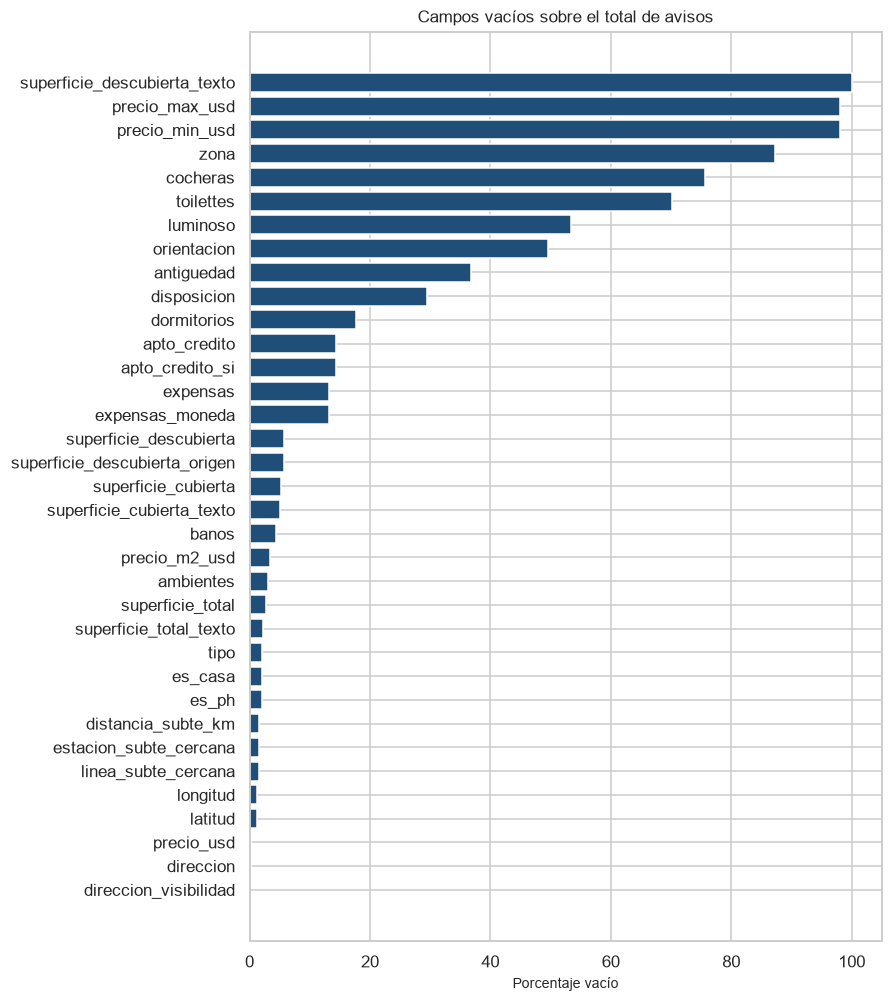

superficie_descubierta_texto está vacía en todos los avisos; superficie_descubierta numérica no.


In [5]:
faltantes = df.isna().mean().mul(100)
faltantes = faltantes[faltantes > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 9), constrained_layout=True)
ax.barh(faltantes.index, faltantes.values, color=COLOR)
ax.set_xlabel("Porcentaje vacío")
ax.set_title("Campos vacíos sobre el total de avisos")
ax.xaxis.set_major_formatter(eje_miles(0))
plt.show()

print("superficie_descubierta_texto está vacía en todos los avisos; superficie_descubierta numérica no.")


## Estadística descriptiva

p10, p25, p50, media, p75 y p90 sobre los valores que caen en el rango plausible.
`min` y `max` son el menor y el mayor valor publicado, incluidos los que caen afuera de ese rango.
`fuera_de_rango` cuenta los que tenían dato y quedaron afuera.
La media cruda del precio no se puede leer: un máximo absurdo la arrastra.


In [6]:
def resumen_numerico(nombres):
    filas = []
    for nombre in nombres:
        serie = df[nombre]
        piso, techo = LIMITES[nombre]
        plausible = serie[serie.between(piso, techo)]
        observada = serie.dropna()
        cuantiles = plausible.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
        filas.append(
            {
                "variable": NOMBRES.get(nombre, nombre),
                "n": int(plausible.shape[0]),
                "faltantes_%": 100 * serie.isna().mean(),
                "fuera_de_rango": int((serie.notna() & ~serie.between(piso, techo)).sum()),
                "min": observada.min() if len(observada) else np.nan,
                "p10": cuantiles.loc[0.10],
                "p25": cuantiles.loc[0.25],
                "p50": cuantiles.loc[0.50],
                "media": plausible.mean(),
                "p75": cuantiles.loc[0.75],
                "p90": cuantiles.loc[0.90],
                "max": observada.max() if len(observada) else np.nan,
            }
        )
    tabla = pd.DataFrame(filas)
    decimales = {
        "Precio publicado (USD)": 0,
        "Precio por m² (USD)": 0,
        "Expensas (ARS)": 0,
        "Fotos del aviso": 0,
        "Ambientes": 1,
        "Dormitorios": 1,
        "Baños": 1,
        "Toilettes": 1,
        "Cocheras": 1,
        "Antigüedad (años)": 0,
    }
    vista = tabla.copy()
    vista["faltantes_%"] = tabla["faltantes_%"].map(lambda valor: miles(valor, 1))
    for columna in ["min", "p10", "p25", "p50", "media", "p75", "p90", "max"]:
        vista[columna] = [
            miles(valor, decimales.get(variable, 1))
            for variable, valor in zip(tabla["variable"], tabla[columna])
        ]
    return vista


display(
    resumen_numerico(
        [
            "precio_usd",
            "precio_m2_usd",
            "superficie_total",
            "superficie_cubierta",
            "superficie_descubierta",
            "ambientes",
            "dormitorios",
            "banos",
            "toilettes",
            "cocheras",
            "antiguedad",
            "expensas",
            "distancia_subte_km",
            "fotos",
        ]
    )
)

precio = df["precio_usd"]
plausible = precio[en_rango(precio, "precio_usd")]
display(
    Markdown(
        f"Media cruda de precio_usd: **{miles(precio.mean())}**. "
        f"Máximo: **{miles(precio.max())}**. "
        f"En el rango plausible la media es **{miles(plausible.mean())}** "
        f"y la mediana **{miles(plausible.median())}** "
        f"({miles(100 * plausible.shape[0] / precio.notna().sum(), 1)}% de los precios con dato)."
    )
)


,variable,n,faltantes_%,fuera_de_rango,min,p10,p25,p50,media,p75,p90,max
0,Precio publicado (USD),85958,"0,2",560,0,75.000,102.000,156.900,248.986,263.000,475.000,940.000.000
1,Precio por m² (USD),83452,"3,5",244,0,1.239,1.714,2.308,2.525,3.021,3.898,2.764.706
2,Superficie total (m²),84103,"2,8",157,"1,0","35,0","46,0","70,0","102,2","119,0","208,0","3.121.000,0"
3,Superficie cubierta (m²),82004,"5,2",203,"1,0","32,0","41,0","60,0","84,7","98,0","166,0","105.280,0"
4,Superficie descubierta (m²),81736,"5,7",35,"0,0","0,0","0,0","6,0","17,9","16,0","46,0","3.120.823,0"
5,Ambientes,83931,"3,0",138,"1,0","1,0","2,0","3,0","2,9","4,0","5,0","4.096,0"
6,Dormitorios,71332,"17,6",85,"1,0","1,0","1,0","2,0","2,1","3,0","3,0","60,0"
7,Baños,82853,"4,4",57,"1,0","1,0","1,0","1,0","1,5","2,0","3,0","55,0"
8,Toilettes,25824,"70,2",8,"1,0","1,0","1,0","1,0","1,1","1,0","1,0","11,0"
9,Cocheras,21000,"75,7",97,"1,0","1,0","1,0","1,0","1,3","1,0","2,0","1.575,0"


Media cruda de precio_usd: **261.261**. Máximo: **940.000.000**. En el rango plausible la media es **248.986** y la mediana **156.900** (99,4% de los precios con dato).

## Distribuciones

En las variables continuas la curva es una densidad (kernel). La línea roja es la mediana
y la verde punteada es la media, calculadas con todos los valores del rango plausible.
Si hay más de 25.000 observaciones, la curva usa una muestra de ese tamaño.

En los conteos enteros el gráfico es un histograma: ambientes, baños, fotos y también
antigüedad, porque los años publicados son enteros; en el histograma van de a 5 años y, desde los 50, en un solo tramo. En categorías de hasta
10 niveles, también. Barrio tiene más de 10 niveles: entra en el mapa y en el gráfico de
medianas, no en un histograma.


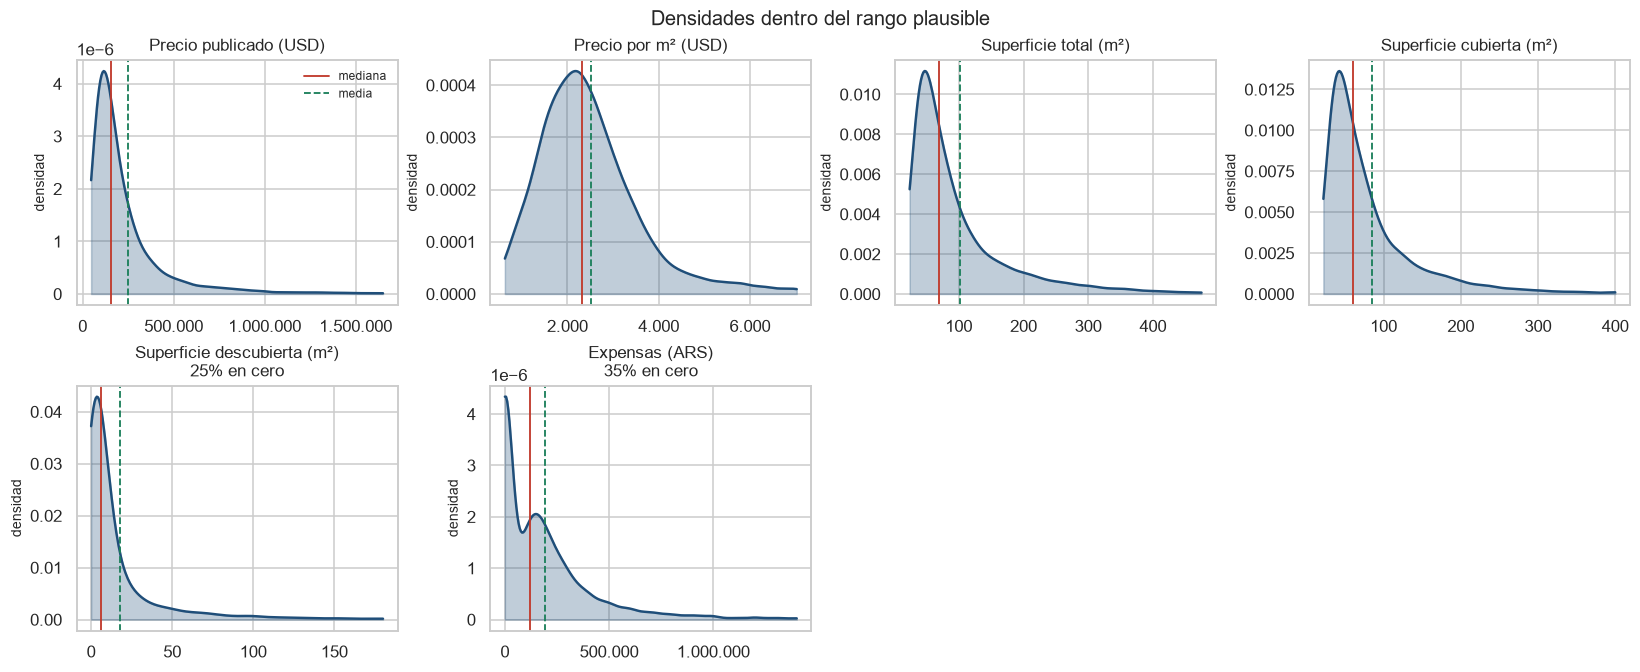

In [7]:
def densidad(ax, serie, titulo, leyenda):
    serie = serie.replace([np.inf, -np.inf], np.nan).dropna()
    ax.set_title(titulo)
    if len(serie) < 40 or serie.nunique() < 5 or serie.std() == 0:
        ax.text(0.5, 0.5, "sin variación suficiente", ha="center", va="center", transform=ax.transAxes)
        return
    muestra = serie.sample(25_000, random_state=0) if len(serie) > 25_000 else serie
    piso, techo = muestra.quantile(0.01), muestra.quantile(0.99)
    if piso == techo:
        piso, techo = muestra.min(), muestra.max()
    xs = np.linspace(piso, techo, 256)
    curva = gaussian_kde(muestra)(xs)
    ax.fill_between(xs, curva, color=COLOR, alpha=0.28)
    ax.plot(xs, curva, color=COLOR, lw=1.6)
    ax.axvline(serie.median(), color=ACENTO, lw=1.2, label="mediana")
    ax.axvline(serie.mean(), color=VERDE, lw=1.2, ls="--", label="media")
    ax.set_ylabel("densidad")
    if serie.max() >= 1000:
        ax.xaxis.set_major_formatter(eje_miles(0))
    if leyenda:
        ax.legend(frameon=False, fontsize=8)


continuas = [
    "precio_usd",
    "precio_m2_usd",
    "superficie_total",
    "superficie_cubierta",
    "superficie_descubierta",
    "expensas",
]
fig, axes = grilla(len(continuas), columnas=4, alto=3.0, ancho=3.7)
for ax, nombre in zip(axes, continuas):
    serie = df.loc[en_rango(df[nombre], nombre), nombre]
    titulo = NOMBRES[nombre]
    if nombre in {"superficie_descubierta", "expensas"}:
        titulo += f"\n{miles(100 * (serie == 0).mean(), 0)}% en cero"
    densidad(ax, serie, titulo, leyenda=nombre == "precio_usd")
fig.suptitle("Densidades dentro del rango plausible", fontsize=13)
plt.show()


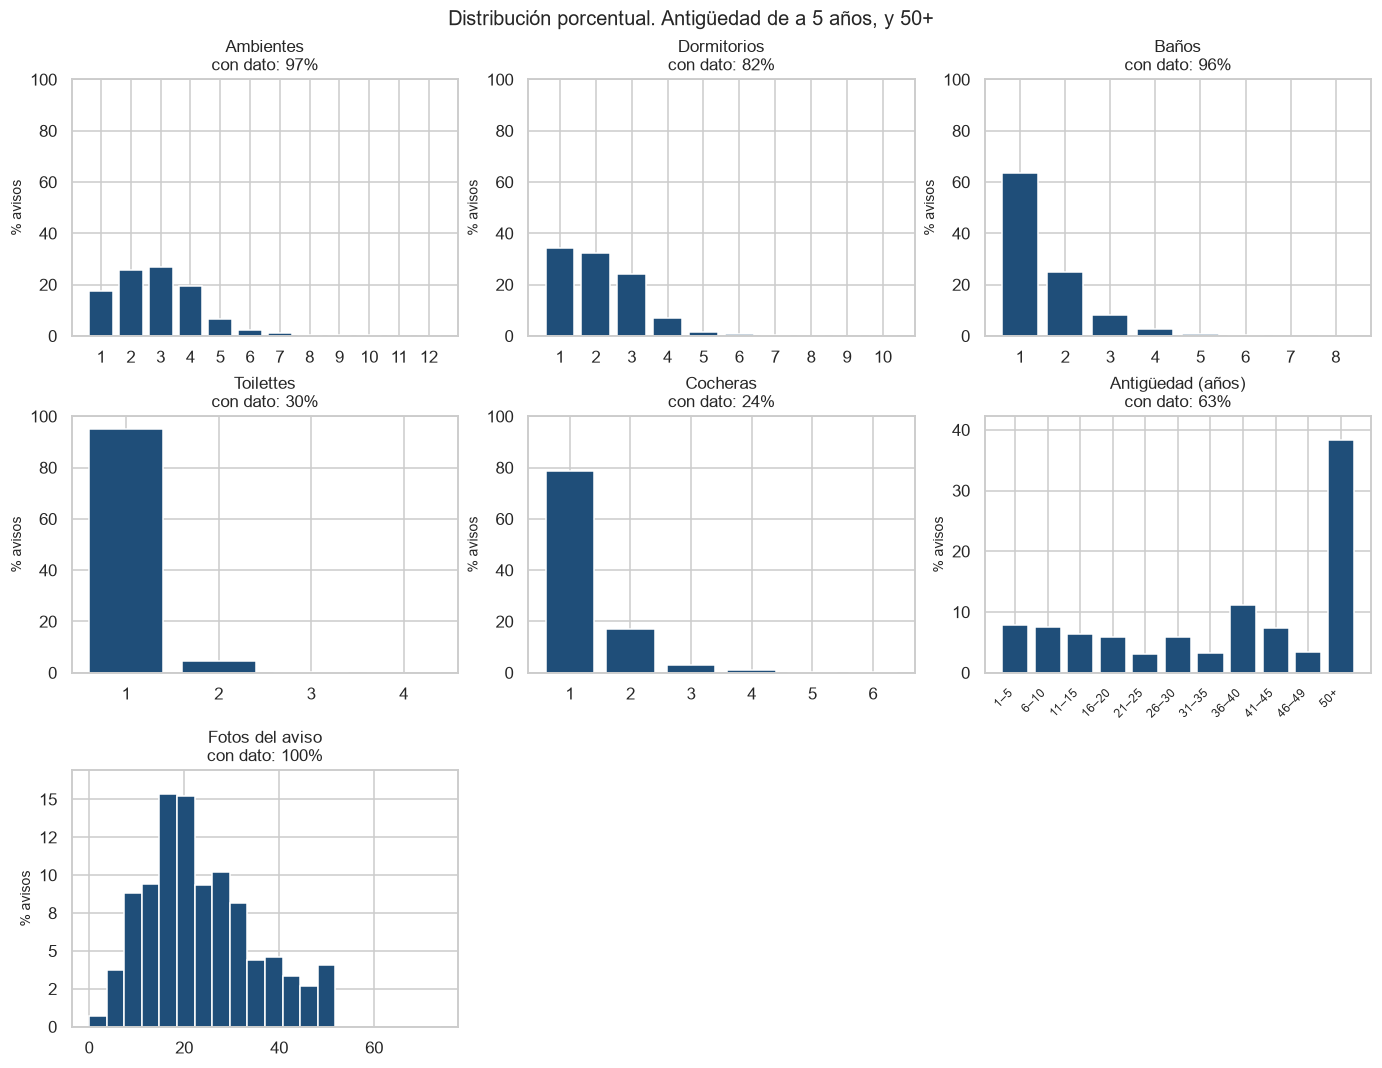

In [8]:
discretas = ["ambientes", "dormitorios", "banos", "toilettes", "cocheras", "antiguedad", "fotos"]
fig, axes = grilla(len(discretas), columnas=3, alto=3.2)
for ax, nombre in zip(axes, discretas):
    serie = df.loc[en_rango(df[nombre], nombre), nombre].dropna()
    ax.set_title(f"{NOMBRES[nombre]}\ncon dato: {miles(100 * df[nombre].notna().mean(), 0)}%")
    n_total = len(serie)
    if n_total == 0:
        ax.text(0.5, 0.5, "sin datos", ha="center", va="center", transform=ax.transAxes)
        continue

    if serie.nunique() <= 12:
        conteo = serie.round().astype(int).value_counts(normalize=True).sort_index()
        ax.bar(conteo.index.astype(str), 100 * conteo.values, color=COLOR)
        ax.set_ylabel("% avisos")
        ax.set_ylim(0, 100)
        ax.yaxis.set_major_formatter(eje_miles(0))
    elif nombre == "antiguedad":
        bordes = np.arange(0, 51, 5)
        grupos = pd.cut(serie[serie < 50], bordes, right=True)
        conteo = grupos.value_counts(sort=False)
        etiquetas = [f"{int(intervalo.left) + 1}\u2013{int(intervalo.right)}" for intervalo in conteo.index]
        etiquetas[-1] = "46\u201349"
        porcentajes = (100 * conteo.to_numpy() / n_total).tolist()
        etiquetas.append("50+")
        porcentajes.append(100 * (serie >= 50).sum() / n_total)
        ax.bar(etiquetas, porcentajes, color=COLOR)
        ax.set_ylabel("% avisos")
        ax.set_ylim(0, max(porcentajes) * 1.1)
        ax.yaxis.set_major_formatter(eje_miles(0))
        ax.tick_params(axis="x", labelrotation=45, labelsize=8)
        for etiqueta in ax.get_xticklabels():
            etiqueta.set_ha("right")
    else:
        counts, bins, patches = ax.hist(serie, bins=20, color=COLOR, edgecolor="white", weights=np.ones(n_total) * 100.0 / n_total)
        ax.set_ylabel("% avisos")
        ax.set_ylim(0, max(counts)*1.1 if len(counts) > 0 else 1)
        ax.yaxis.set_major_formatter(eje_miles(0))
fig.suptitle("Distribución porcentual. Antigüedad de a 5 años, y 50+", fontsize=13)
plt.show()


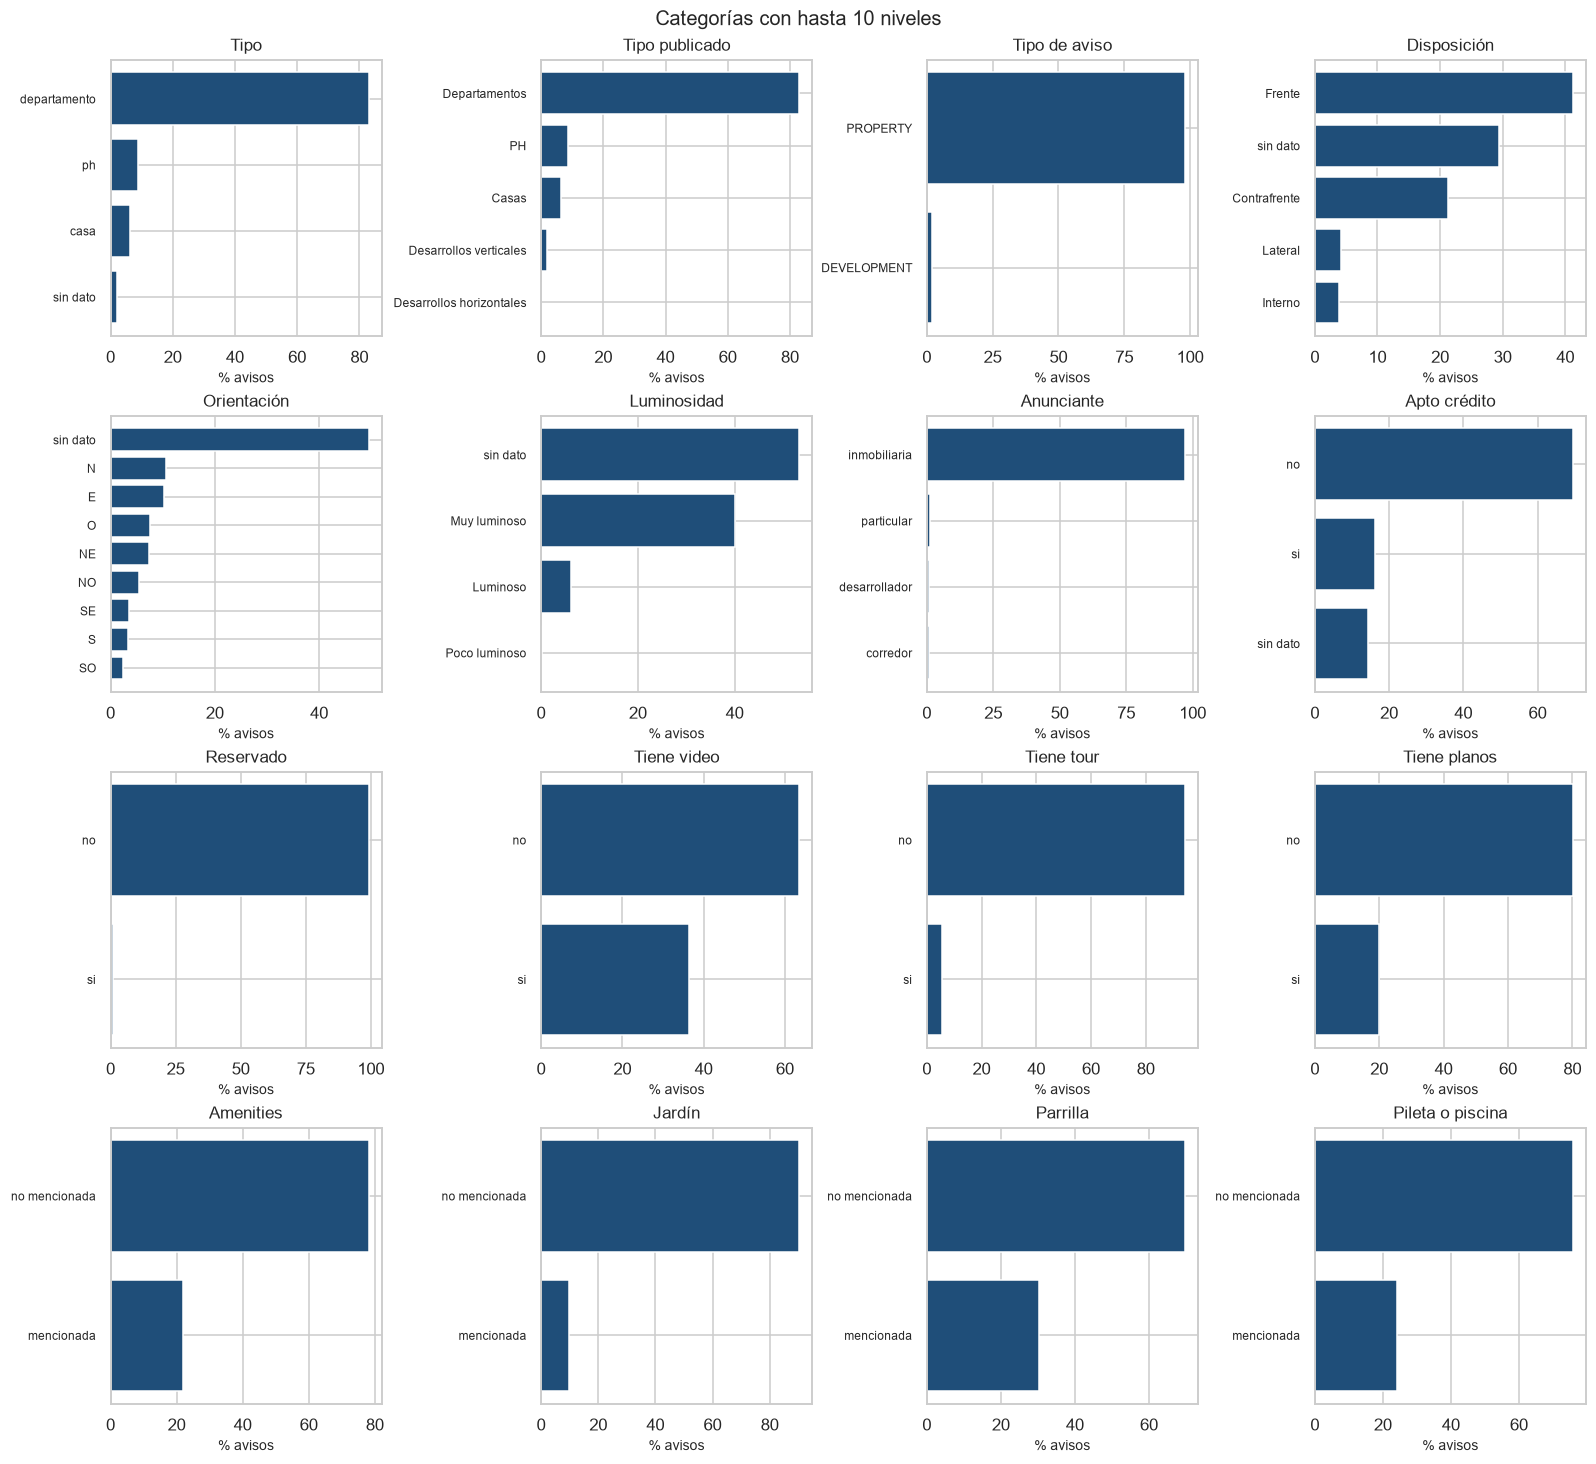

In [9]:
categoricas = [
    "tipo",
    "tipo_publicado",
    "tipo_aviso",
    "disposicion",
    "orientacion",
    "luminoso",
    "tipo_anunciante",
    "apto_credito",
    "reservado",
    "tiene_video",
    "tiene_tour",
    "tiene_planos",
    *FLAGS,
]
elegibles = []
for nombre in categoricas:
    niveles = df[nombre].fillna("sin dato").nunique(dropna=False)
    if 2 <= niveles <= 10:
        elegibles.append(nombre)

fig, axes = grilla(len(elegibles), columnas=4, alto=3.3, ancho=3.6)
for ax, nombre in zip(axes, elegibles):
    if nombre in FLAGS:
        serie = df[nombre].map({0.0: "no mencionada", 1.0: "mencionada"})
    else:
        serie = df[nombre].fillna("sin dato").astype(str)
    conteo = serie.value_counts(normalize=True) * 100  # porcentaje
    ax.barh(conteo.index.astype(str)[::-1], conteo.values[::-1], color=COLOR)
    ax.set_title(NOMBRES.get(nombre, nombre))
    ax.set_xlabel("% avisos")
    ax.xaxis.set_major_formatter(eje_miles(0))
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Categorías con hasta 10 niveles", fontsize=13)
plt.show()


## Outliers

Dos cosas distintas. La primera son valores imposibles (precio 0, precio de cientos de
millones, superficie que no es una vivienda): quedan fuera del rango. La segunda son
outliers estadísticos **dentro** del rango: puntos más allá de 1,5 veces el rango
intercuartil. En un precio tan asimétrico, la cola alta del rango plausible es real
(Puerto Madero, casas grandes) y aun así cae fuera de las antenas del boxplot.
En cocheras el cuartil 1 y el 3 son 1, el cerco se cierra y cualquier aviso con
más de una cochera queda marcado. Eso no es un error de carga.


In [10]:
extremos = []
for nombre, (piso, techo) in LIMITES.items():
    serie = df[nombre].dropna()
    extremos.append(
        {
            "variable": NOMBRES[nombre],
            "minimo": serie.min(),
            "p99": serie.quantile(0.99),
            "maximo": serie.max(),
            "n_bajo": int((serie < piso).sum()),
            "n_alto": int((serie > techo).sum()),
        }
    )
tabla_extremos = pd.DataFrame(extremos)
vista = tabla_extremos.copy()
for columna in ["minimo", "p99", "maximo"]:
    vista[columna] = [
        miles(valor, 0 if abs(valor) >= 100 else 1)
        for valor in tabla_extremos[columna]
    ]
display(vista)

columnas_aviso = ["precio_usd", "precio_m2_usd", "superficie_total", "ambientes", "barrio", "tipo", "titulo"]
display(Markdown("**Ocho precios publicados más altos.** El máximo no es un departamento."))
display(df.nlargest(8, "precio_usd")[columnas_aviso])
display(Markdown("**Ocho superficies totales más altas.**"))
display(df.nlargest(8, "superficie_total")[columnas_aviso])


,variable,minimo,p99,maximo,n_bajo,n_alto
0,Precio publicado (USD),"0,0",1.700.000,940.000.000,525,35
1,Precio por m² (USD),"0,0",7.302,2.764.706,177,67
2,Superficie total (m²),"1,0",498,3.121.000,73,84
3,Superficie cubierta (m²),"1,0",400,105.280,134,69
4,Superficie descubierta (m²),"0,0",180,3.120.823,0,35
5,Ambientes,"1,0","8,0",4.096,0,138
6,Dormitorios,"1,0","6,0","60,0",0,85
7,Baños,"1,0","5,0","55,0",0,57
8,Toilettes,"1,0","2,0","11,0",0,8
9,Cocheras,"1,0","4,0",1.575,0,97


**Ocho precios publicados más altos.** El máximo no es un departamento.

,precio_usd,precio_m2_usd,superficie_total,ambientes,barrio,tipo,titulo
30437,940000000.0,2764705.88,340.0,7.0,Belgrano,departamento,7 Ambientes Exclusivo Piso Alto Barrancas Belg...
24674,12400000.0,NaN,NaN,14.0,Palermo,casa,Casa en Venta Renovada en Palermo Chico
50367,12000000.0,3564.00,3367.0,32.0,Belgrano,casa,"Casa Triplex en Venta en Belgrano, Capital Fed..."
50371,12000000.0,3564.00,3367.0,8.0,Belgrano,departamento,Departamento Piso en Venta Ubicado en Belgrano...
79824,11111111.0,194931.77,57.0,2.0,Villa Devoto,departamento,Departamento 2 Amb con Patio y Balcon
125,10000000.0,3566.33,2804.0,25.0,Retiro,casa,Mansión en Plaza San Martín de Categoría Premi...
149,10000000.0,3566.33,2804.0,25.0,Recoleta,casa,Mansión en Venta en Plaza San Martín de Catego...
150,10000000.0,3566.33,2804.0,25.0,Barrio Norte,casa,Mansión en Venta en Plaza San Martín de Catego...


**Ocho superficies totales más altas.**

,precio_usd,precio_m2_usd,superficie_total,ambientes,barrio,tipo,titulo
10259,445000.0,0.14,3121000.0,5.0,Villa Pueyrredón,casa,"Casa en Villa Pueyrredon 5 Ambientes, Cochera,..."
33602,1693220.0,4.46,380000.0,4.0,Belgrano,departamento,Departamento Venta 4 Ambientes Belgrano
35926,340000.0,1.00,340000.0,3.0,Recoleta,departamento,Oportunidad 3ambientes en Venta C/ Dependencia...
10116,380000.0,2.38,160000.0,4.0,Mataderos,departamento,Departamento a Estrnar
46953,240000.0,1.51,159410.0,4.0,Villa Urquiza,ph,"PH 3 Dorm. Entrada Independient, Villa Urquiza"
17844,730000.0,4.87,150000.0,4.0,Palermo,departamento,Expectacular Duplex en Torre de Categoría con ...
49585,178000.0,1.68,106000.0,4.0,Caballito,departamento,"Caballito, 4 Ambientes, balcon Luminoso"
78410,252000.0,2.39,105298.0,4.0,Villa Crespo,ph,Amplio PH 4 Ambientes en Villa Crespo


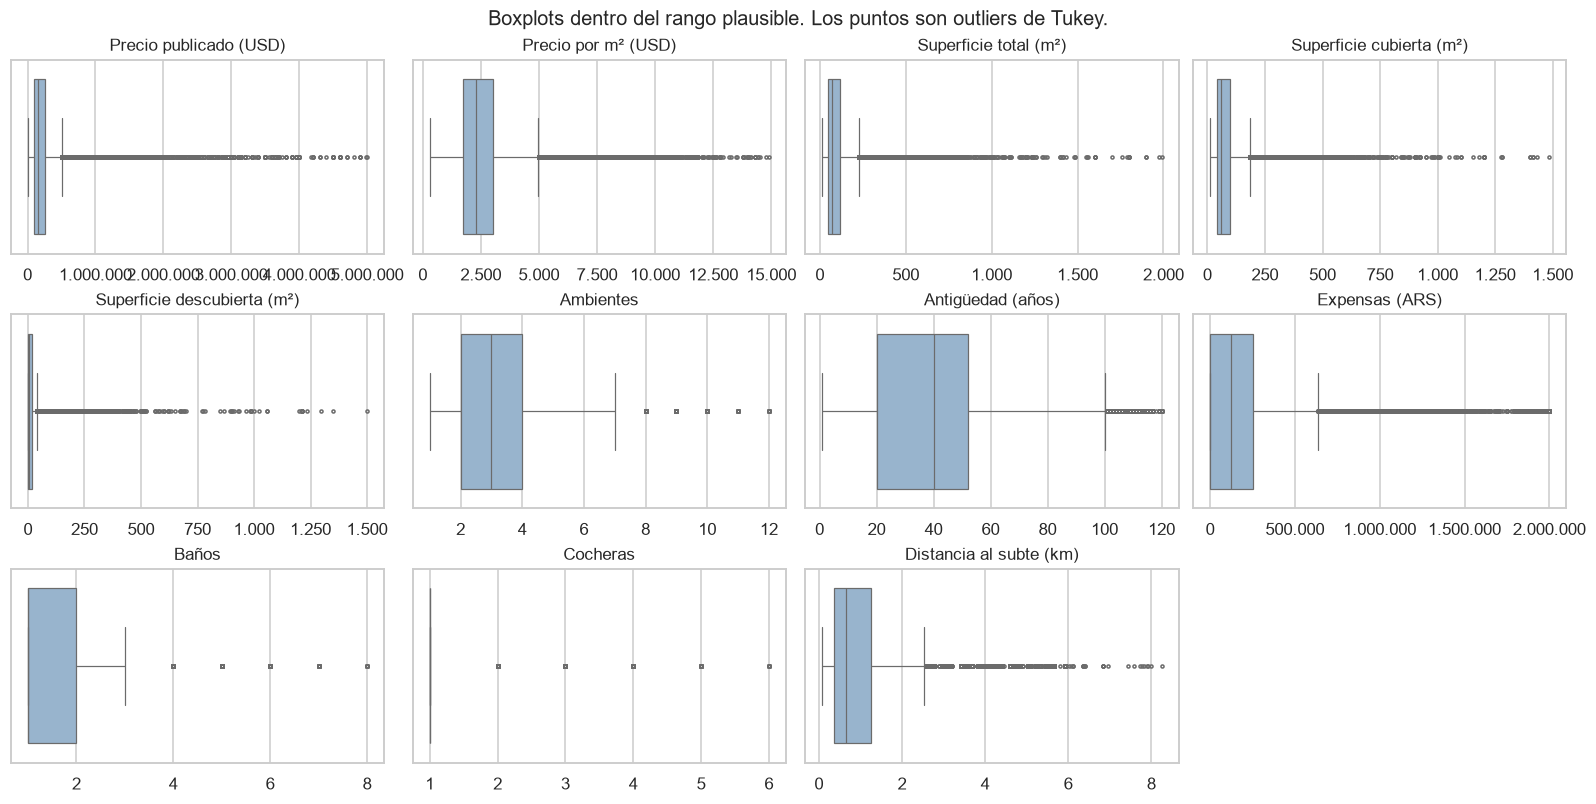

,variable,cerco_inf,cerco_sup,n_bajo,n_alto,alto_%
0,Precio publicado (USD),"-139.499,6","504.499,4",0,7659,"8,9"
1,Precio por m² (USD),"-245,5","4.980,6",0,3880,"4,6"
2,Superficie total (m²),"-63,5","228,5",0,6920,"8,2"
3,Superficie cubierta (m²),"-44,5","183,5",0,6470,"7,9"
4,Superficie descubierta (m²),"-24,0","40,0",0,9304,"11,4"
5,Ambientes,"-1,0","7,0",0,797,"0,9"
6,Antigüedad (años),"-28,0","100,0",0,234,"0,4"
7,Expensas (ARS),"-381.000,0","635.000,0",0,4644,"6,2"
8,Baños,"-0,5","3,5",0,3108,"3,8"
9,Cocheras,"1,0","1,0",0,4496,"21,4"


In [11]:
def serie_plausible(nombre):
    return df.loc[en_rango(df[nombre], nombre), nombre].dropna()


cajas = [
    "precio_usd",
    "precio_m2_usd",
    "superficie_total",
    "superficie_cubierta",
    "superficie_descubierta",
    "ambientes",
    "antiguedad",
    "expensas",
    "banos",
    "cocheras",
    "distancia_subte_km",
]
fig, axes = grilla(len(cajas), columnas=4, alto=2.4, ancho=3.6)
iqr_filas = []
for ax, nombre in zip(axes, cajas):
    serie = serie_plausible(nombre)
    sns.boxplot(x=serie, ax=ax, color="#8fb4d6", fliersize=2, linewidth=0.8)
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_title(NOMBRES[nombre])
    if serie.max() >= 1000:
        ax.xaxis.set_major_formatter(eje_miles(0))
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    ancho_iqr = q3 - q1
    inferior, superior = q1 - 1.5 * ancho_iqr, q3 + 1.5 * ancho_iqr
    iqr_filas.append(
        {
            "variable": NOMBRES[nombre],
            "cerco_inf": inferior,
            "cerco_sup": superior,
            "n_bajo": int((serie < inferior).sum()),
            "n_alto": int((serie > superior).sum()),
            "alto_%": 100 * (serie > superior).mean(),
        }
    )
fig.suptitle("Boxplots dentro del rango plausible. Los puntos son outliers de Tukey.", fontsize=13)
plt.show()

iqr = pd.DataFrame(iqr_filas)
vista_iqr = iqr.copy()
for columna in ["cerco_inf", "cerco_sup"]:
    vista_iqr[columna] = [miles(valor, 1) for valor in iqr[columna]]
vista_iqr["alto_%"] = iqr["alto_%"].map(lambda valor: miles(valor, 1))
display(vista_iqr)


## Precio en USD contra otras variables

En los hexágonos, el color es la cantidad de avisos (en log) y la línea roja es la mediana
del precio dentro de cada decil de la variable del eje x. El eje del precio está en log
para que la masa de avisos de 100.000 a 300.000 USD no quede aplastada.

El precio total sube con los metros casi por construcción. El precio por m² sirve para ver
si el barrio, la amenidad o el tipo cambian el valor del metro y no solo el tamaño.


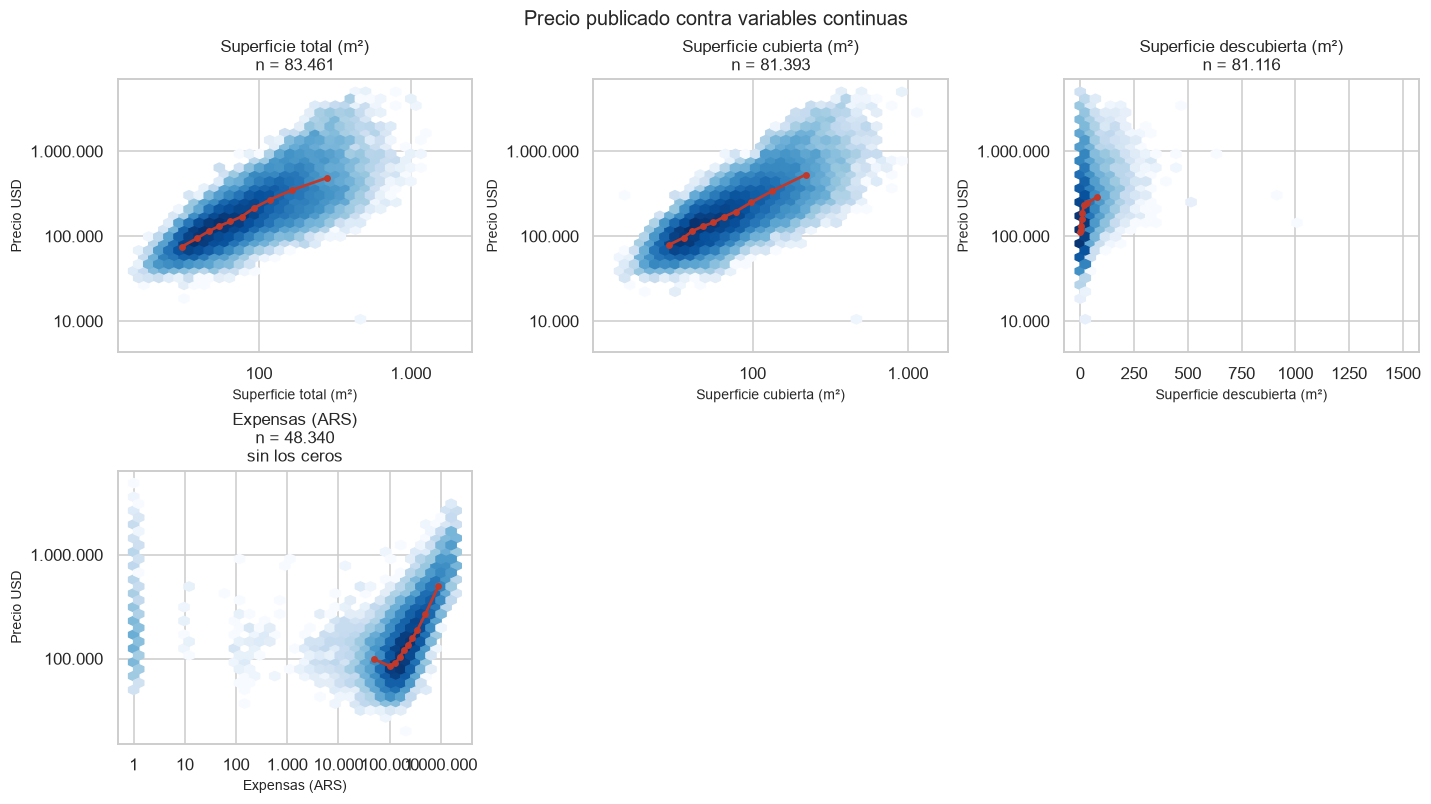

In [12]:
def marcas_log(valores):
    piso, techo = float(np.min(valores)), float(np.max(valores))
    exponentes = np.arange(np.floor(np.log10(piso)), np.ceil(np.log10(techo)) + 1)
    marcas = 10.0 ** exponentes
    return marcas[(marcas >= piso) & (marcas <= techo)]


def hex_precio(ax, nombre, escala_x):
    piso_y, techo_y = LIMITES["precio_usd"]
    datos = pd.DataFrame({"x": df[nombre], "y": df["precio_usd"]}).dropna()
    datos = datos[datos["y"].between(piso_y, techo_y)]
    if nombre in LIMITES:
        piso_x, techo_x = LIMITES[nombre]
        datos = datos[datos["x"].between(piso_x, techo_x)]
    if escala_x == "log":
        datos = datos[datos["x"] > 0]
    titulo = f"{NOMBRES[nombre]}\nn = {miles(len(datos))}"
    if nombre == "expensas":
        titulo += "\nsin los ceros"
    ax.set_title(titulo)
    if len(datos) < 80:
        ax.text(0.5, 0.5, "pocos datos", ha="center", va="center", transform=ax.transAxes)
        return
    # El hexágono y la mediana viven en la misma escala. El eje se etiqueta en unidades originales.
    x = np.log10(datos["x"]) if escala_x == "log" else datos["x"].to_numpy()
    y = np.log10(datos["y"].to_numpy())
    ax.hexbin(x, y, gridsize=32, cmap="Blues", mincnt=3, bins="log")
    datos = datos.copy()
    datos["bin"] = pd.qcut(datos["x"], 10, duplicates="drop")
    tendencia = datos.groupby("bin", observed=True).agg(x=("x", "median"), y=("y", "median"))
    x_linea = np.log10(tendencia["x"]) if escala_x == "log" else tendencia["x"]
    ax.plot(x_linea, np.log10(tendencia["y"]), color=ACENTO, marker="o", ms=3.5, lw=1.8)
    marcas_y = marcas_log(datos["y"])
    ax.set_yticks(np.log10(marcas_y))
    ax.set_yticklabels([miles(marca) for marca in marcas_y])
    if escala_x == "log":
        marcas_x = marcas_log(datos["x"])
        ax.set_xticks(np.log10(marcas_x))
        ax.set_xticklabels([miles(marca) for marca in marcas_x])
    ax.set_xlabel(NOMBRES[nombre])
    ax.set_ylabel("Precio USD")


paneles = [
    ("superficie_total", "log"),
    ("superficie_cubierta", "log"),
    ("superficie_descubierta", "linear"),
    ("expensas", "log"),
]
fig, axes = grilla(len(paneles), columnas=3, alto=3.6, ancho=4.3)
for ax, (nombre, escala) in zip(axes, paneles):
    hex_precio(ax, nombre, escala)
fig.suptitle("Precio publicado contra variables continuas", fontsize=13)
plt.show()


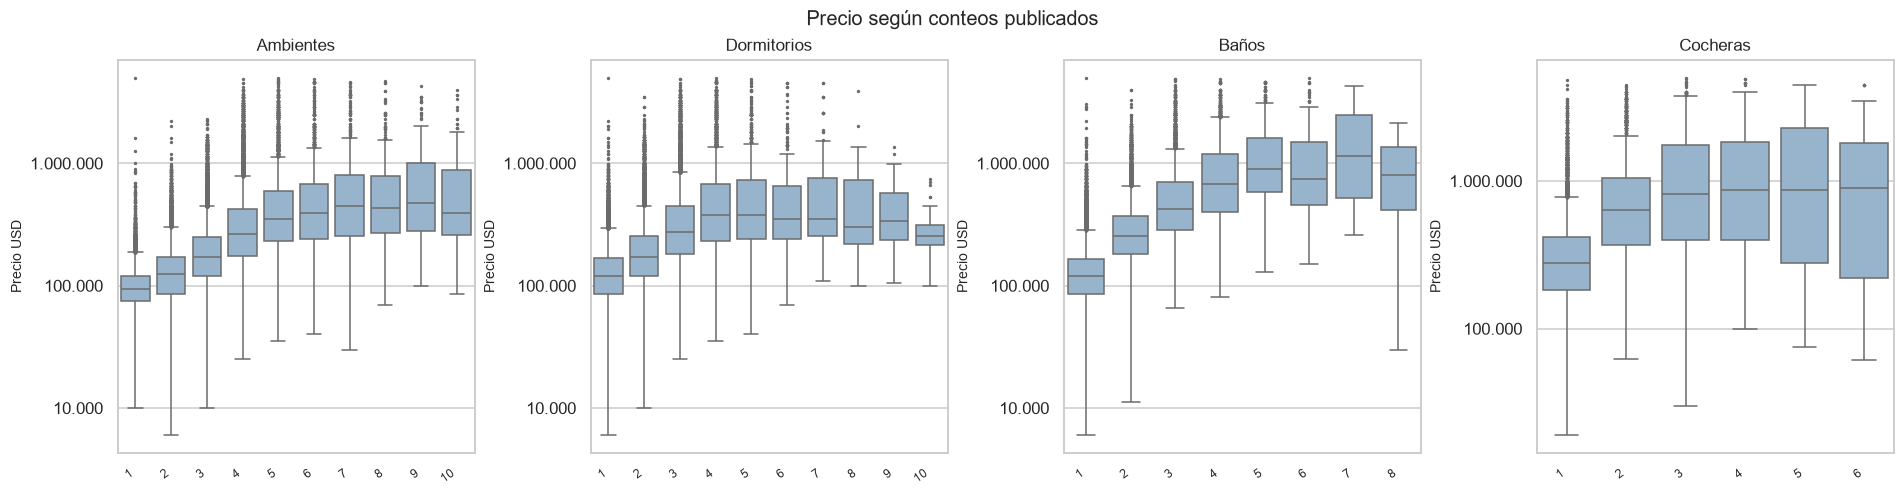

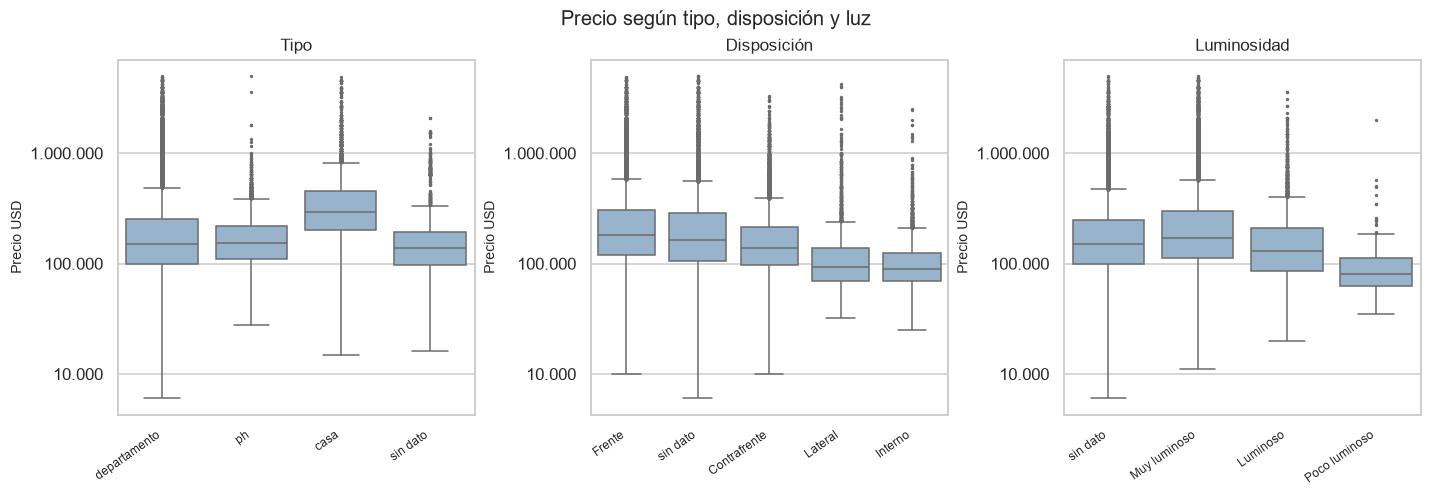

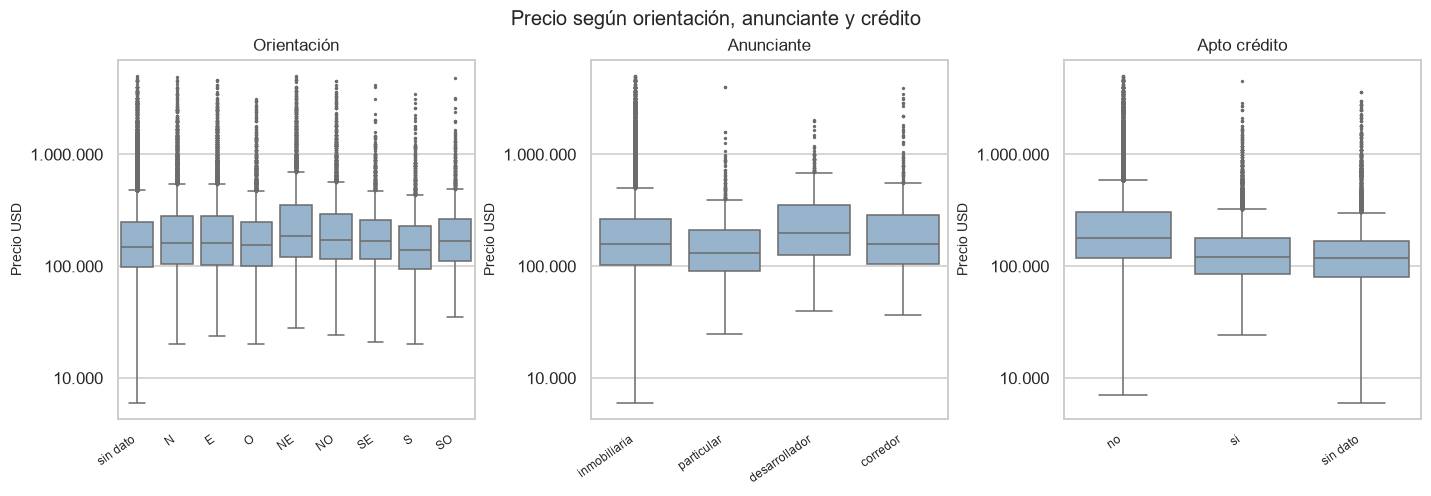

In [13]:
def cajas_vs_precio(columnas, titulo, solo_observadas=False):
    fig, axes = plt.subplots(
        1,
        len(columnas),
        figsize=(4.3 * len(columnas), 4.4),
        constrained_layout=True,
    )
    axes = np.atleast_1d(axes)
    for ax, nombre in zip(axes, columnas):
        datos = df.loc[en_rango(df["precio_usd"], "precio_usd"), [nombre, "precio_usd"]].copy()
        if solo_observadas or nombre in LIMITES:
            if nombre in LIMITES:
                datos = datos.loc[en_rango(datos[nombre], nombre)]
            else:
                datos = datos.dropna()
        if nombre in FLAGS:
            datos[nombre] = datos[nombre].map({0.0: "no mencionada", 1.0: "mencionada"})
        elif pd.api.types.is_numeric_dtype(datos[nombre]):
            datos[nombre] = datos[nombre].round().astype("Int64").astype(str)
        else:
            datos[nombre] = datos[nombre].fillna("sin dato").astype(str)
        orden = datos[nombre].value_counts().index.tolist()
        if len(orden) > 10:
            orden = datos[nombre].value_counts().head(10).index.tolist()
            datos = datos[datos[nombre].isin(orden)]
        if orden and all(str(item).lstrip("-").isdigit() for item in orden):
            orden = sorted(orden, key=lambda item: int(item))
        sns.boxplot(
            data=datos,
            x=nombre,
            y="precio_usd",
            order=orden,
            ax=ax,
            color="#8fb4d6",
            fliersize=1.2,
        )
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(eje_miles(0))
        ax.set_xlabel("")
        ax.set_ylabel("Precio USD")
        ax.set_title(NOMBRES.get(nombre, nombre))
        ax.tick_params(axis="x", labelrotation=35, labelsize=8)
        for etiqueta in ax.get_xticklabels():
            etiqueta.set_ha("right")
    fig.suptitle(titulo, fontsize=13)
    plt.show()


cajas_vs_precio(
    ["ambientes", "dormitorios", "banos", "cocheras"],
    "Precio según conteos publicados",
    solo_observadas=True,
)
cajas_vs_precio(
    ["tipo", "disposicion", "luminoso"],
    "Precio según tipo, disposición y luz",
)
cajas_vs_precio(
    ["orientacion", "tipo_anunciante", "apto_credito"],
    "Precio según orientación, anunciante y crédito",
)


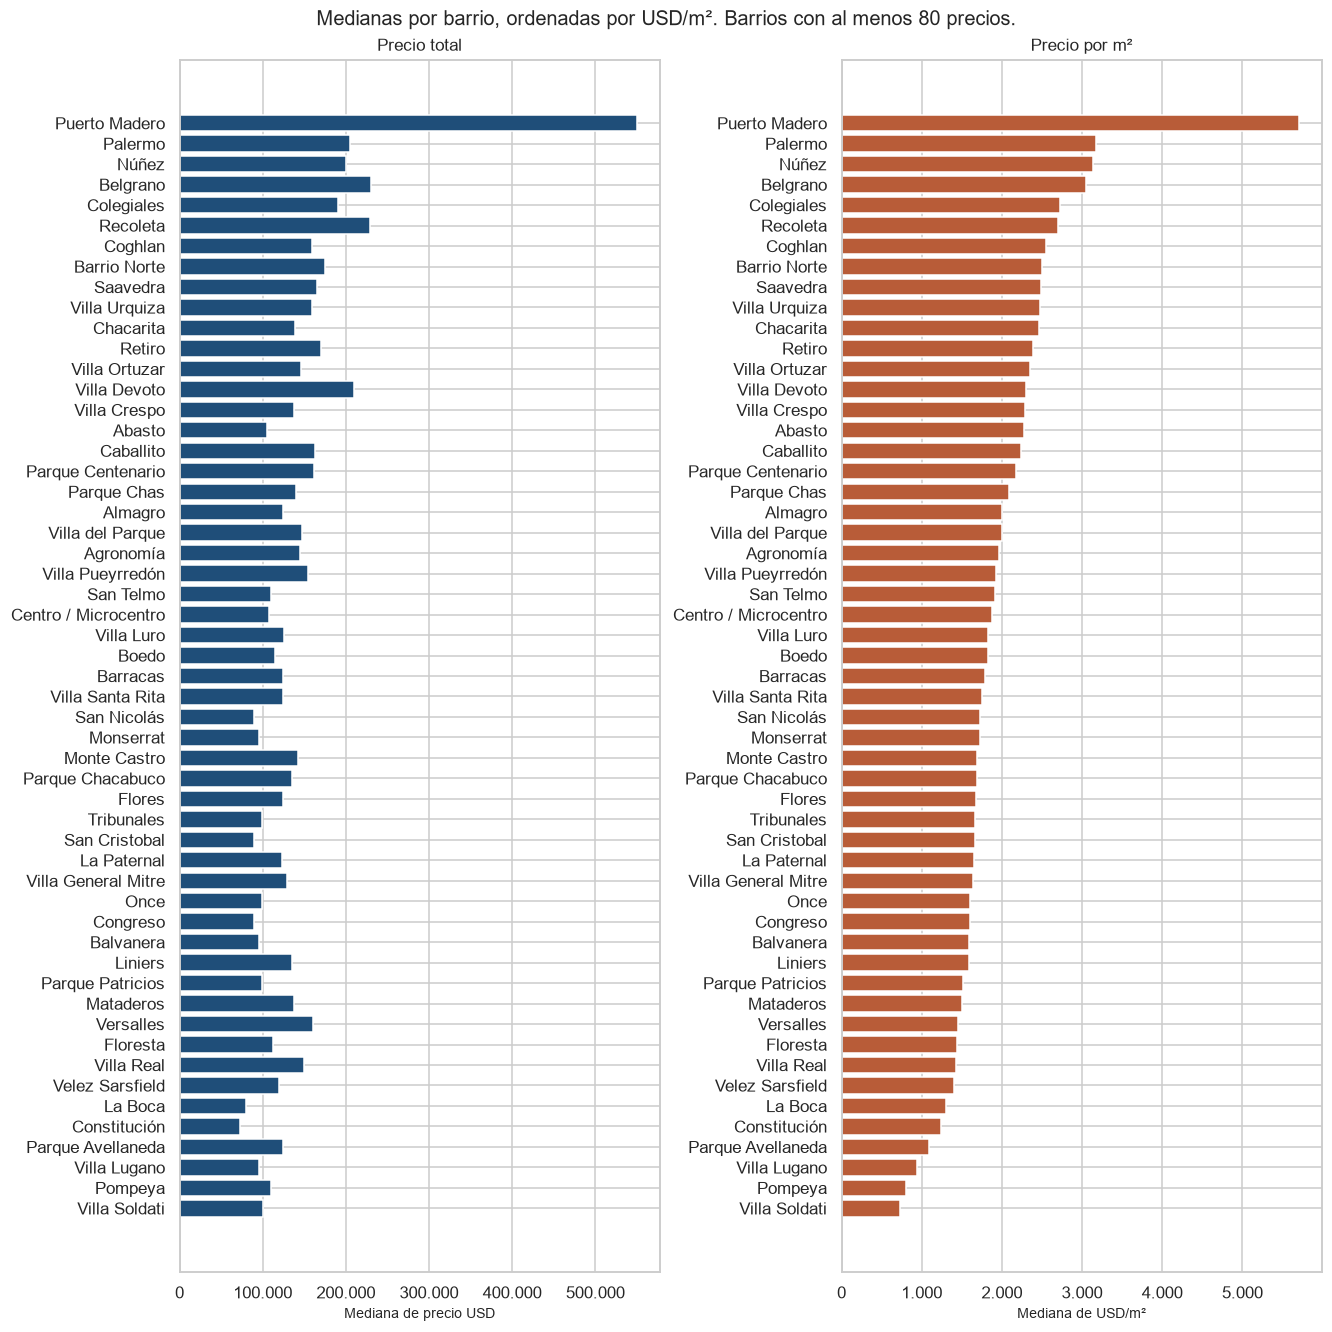

In [14]:
precio_ok = en_rango(df["precio_usd"], "precio_usd")
m2_ok = en_rango(df["precio_m2_usd"], "precio_m2_usd")
por_precio = (
    df.loc[precio_ok]
    .groupby("barrio")
    .agg(n=("precio_usd", "size"), mediana_usd=("precio_usd", "median"))
)
por_m2 = (
    df.loc[m2_ok]
    .groupby("barrio")
    .agg(mediana_m2=("precio_m2_usd", "median"))
)
barrios_precio = por_precio.join(por_m2)
barrios_precio = barrios_precio[barrios_precio["n"] >= 80].sort_values("mediana_m2")

fig, axes = plt.subplots(1, 2, figsize=(12, 12), constrained_layout=True)
axes[0].barh(barrios_precio.index, barrios_precio["mediana_usd"], color=COLOR)
axes[1].barh(barrios_precio.index, barrios_precio["mediana_m2"], color="#b85c38")
axes[0].set_xlabel("Mediana de precio USD")
axes[1].set_xlabel("Mediana de USD/m²")
axes[0].xaxis.set_major_formatter(eje_miles(0))
axes[1].xaxis.set_major_formatter(eje_miles(0))
axes[0].set_title("Precio total")
axes[1].set_title("Precio por m²")
fig.suptitle("Medianas por barrio, ordenadas por USD/m². Barrios con al menos 80 precios.", fontsize=13)
plt.show()


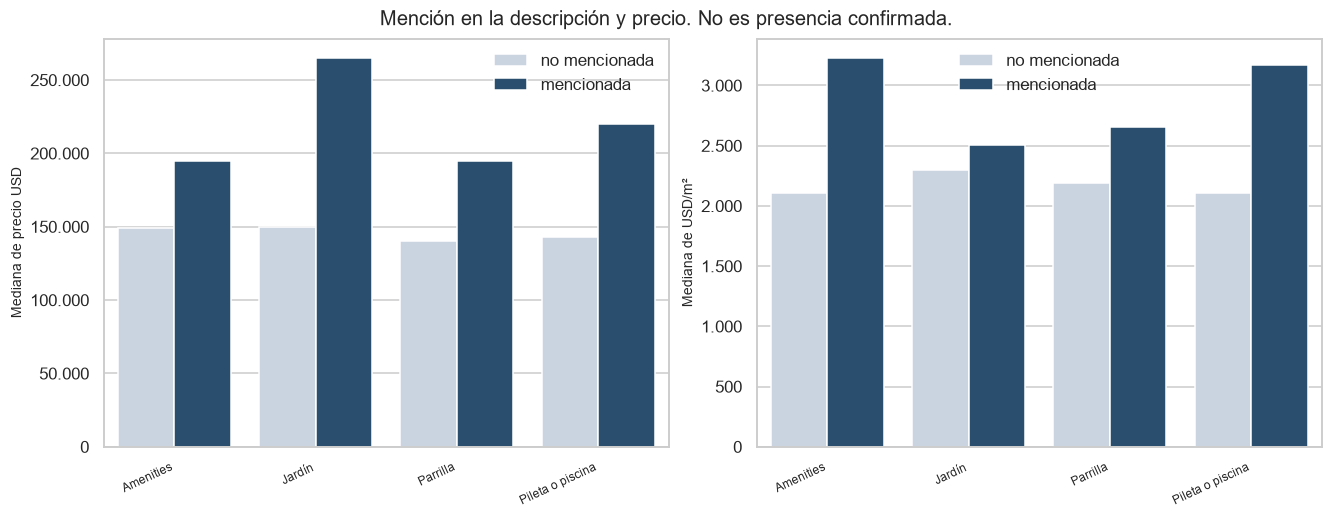

,variable,mencion,n_precio,mediana_usd,mediana_m2
0,Amenities,no mencionada,67235,149.000,2.109
1,Amenities,mencionada,18723,195.000,3.228
2,Jardín,no mencionada,77684,150.000,2.297
3,Jardín,mencionada,8274,265.000,2.507
4,Parrilla,no mencionada,59924,140.000,2.191
5,Parrilla,mencionada,26034,195.000,2.656
6,Pileta o piscina,no mencionada,65355,143.000,2.109
7,Pileta o piscina,mencionada,20603,220.000,3.167


In [15]:
filas_flag = []
for flag in FLAGS:
    for valor, etiqueta in [(0.0, "no mencionada"), (1.0, "mencionada")]:
        filas_flag.append(
            {
                "variable": NOMBRES[flag],
                "mencion": etiqueta,
                "n_precio": int(((df[flag] == valor) & precio_ok).sum()),
                "mediana_usd": df.loc[(df[flag] == valor) & precio_ok, "precio_usd"].median(),
                "mediana_m2": df.loc[(df[flag] == valor) & m2_ok, "precio_m2_usd"].median(),
            }
        )
flags_precio = pd.DataFrame(filas_flag)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
sns.barplot(data=flags_precio, x="variable", y="mediana_usd", hue="mencion", ax=axes[0], palette=["#c5d4e4", COLOR])
sns.barplot(data=flags_precio, x="variable", y="mediana_m2", hue="mencion", ax=axes[1], palette=["#c5d4e4", COLOR])
axes[0].set_ylabel("Mediana de precio USD")
axes[1].set_ylabel("Mediana de USD/m²")
axes[0].yaxis.set_major_formatter(eje_miles(0))
axes[1].yaxis.set_major_formatter(eje_miles(0))
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=25, labelsize=8)
    for etiqueta in ax.get_xticklabels():
        etiqueta.set_ha("right")
    ax.legend(title="", frameon=False)
fig.suptitle("Mención en la descripción y precio. No es presencia confirmada.", fontsize=13)
plt.show()

vista_flags = flags_precio.copy()
vista_flags["mediana_usd"] = flags_precio["mediana_usd"].map(lambda valor: miles(valor, 0))
vista_flags["mediana_m2"] = flags_precio["mediana_m2"].map(lambda valor: miles(valor, 0))
display(vista_flags)


## Correlograma

Spearman, no Pearson: el precio y las superficies son asimétricos y Spearman mira rangos.
Cada par usa los avisos en los que ambas variables caen en su rango plausible.
`precio_m2_usd` no está en la matriz porque es una transformación del precio.

Casa y PH están medidos contra el departamento, que es la base. Un flag en 0 mezcla
"no tiene" y "no lo escribió", así que su correlación con el precio está atenuada.


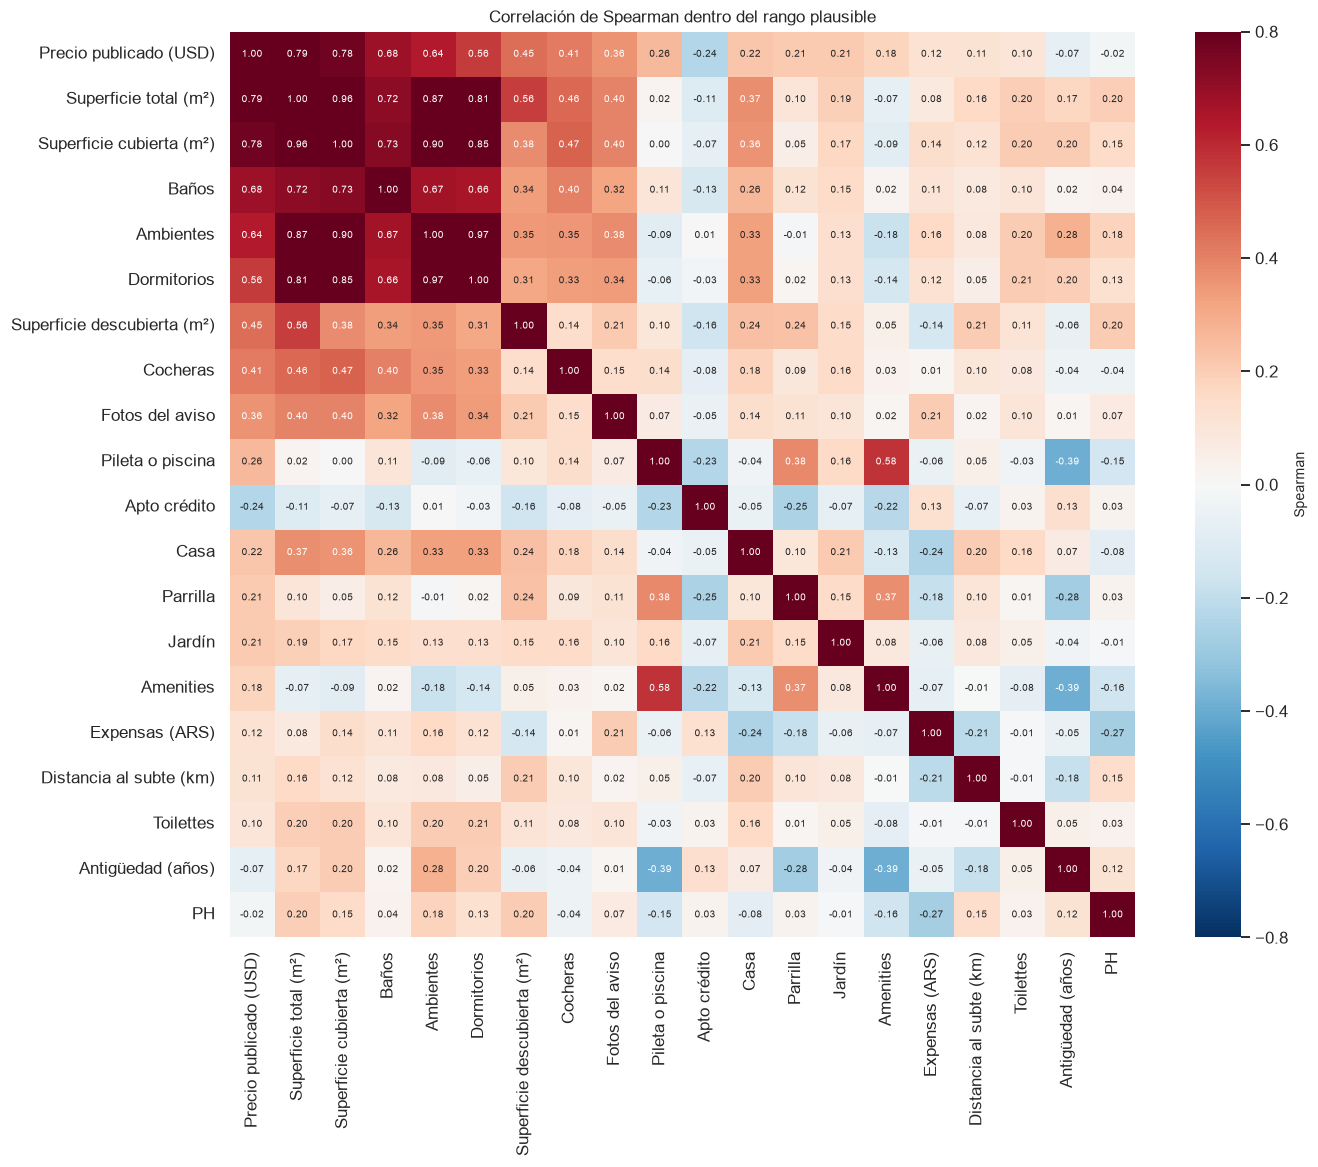

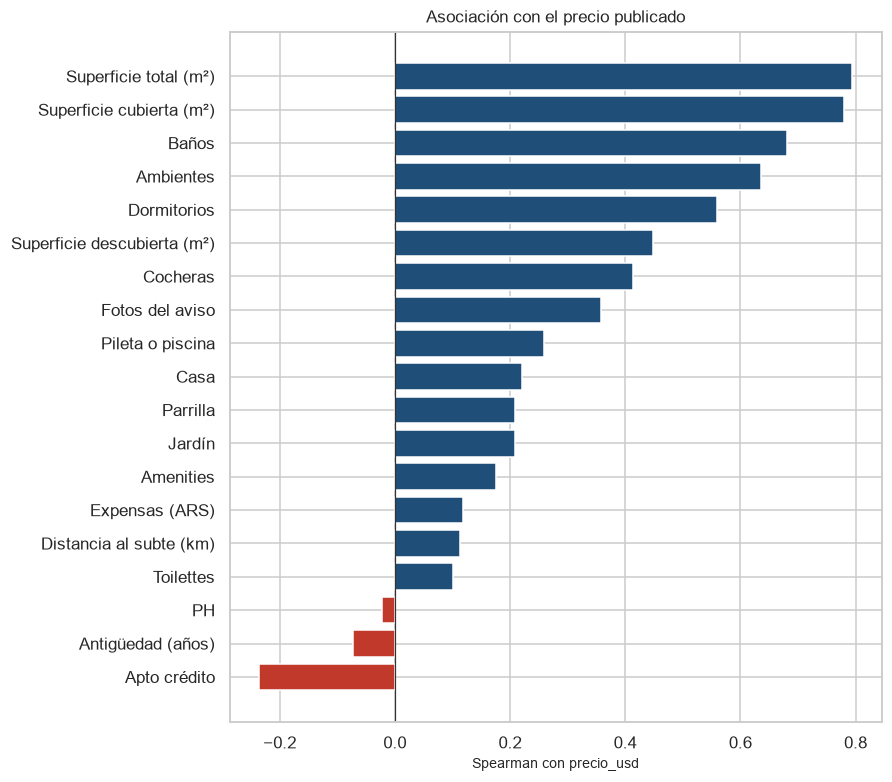

In [16]:
columnas_corr = [
    "precio_usd",
    "superficie_total",
    "superficie_cubierta",
    "superficie_descubierta",
    "ambientes",
    "dormitorios",
    "banos",
    "toilettes",
    "cocheras",
    "antiguedad",
    "expensas",
    "distancia_subte_km",
    "fotos",
    *FLAGS,
    "es_casa",
    "es_ph",
    "apto_credito_si",
]
base = df[columnas_corr].copy()
for nombre in columnas_corr:
    if nombre in LIMITES:
        base.loc[~en_rango(base[nombre], nombre), nombre] = np.nan
rho = base.corr(method="spearman")
rho = rho.dropna(axis=0, how="all").dropna(axis=1, how="all")
orden = rho["precio_usd"].abs().sort_values(ascending=False).index
rho = rho.loc[orden, orden]
etiquetas = [NOMBRES.get(nombre, nombre) for nombre in rho.columns]
rho_plot = rho.copy()
rho_plot.index = etiquetas
rho_plot.columns = etiquetas

fig, ax = plt.subplots(figsize=(12.5, 10.5), constrained_layout=True)
sns.heatmap(
    rho_plot,
    ax=ax,
    cmap="RdBu_r",
    center=0,
    vmin=-0.8,
    vmax=0.8,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 6.5},
    square=True,
    cbar_kws={"label": "Spearman"},
)
ax.set_title("Correlación de Spearman dentro del rango plausible")
plt.show()

asociacion = rho["precio_usd"].drop("precio_usd").sort_values()
fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
colores = [ACENTO if valor < 0 else COLOR for valor in asociacion]
ax.barh([NOMBRES.get(nombre, nombre) for nombre in asociacion.index], asociacion.values, color=colores)
ax.axvline(0, color="#333333", lw=0.8)
ax.set_xlabel("Spearman con precio_usd")
ax.set_title("Asociación con el precio publicado")
plt.show()


## Mapa de valores en CABA

Los polígonos son los barrios oficiales de Buenos Aires Data. El color es la mediana del
precio por m², y el panel de al lado es la mediana del precio total. La escala de color
se corta en los percentiles 5 y 95 para que un solo barrio no apague al resto.

Algunos nombres del aviso no son barrios oficiales (Barrio Norte, Once, Congreso, Tribunales,
Microcentro, Abasto, Parque Centenario, Otro). Esos avisos no entran en el polígono; sí
están en el gráfico de barras de la sección anterior.


Avisos en un barrio con polígono oficial: 95,9%. Sin polígono: Abasto, Barrio Norte, Centro / Microcentro, Congreso, Once, Otro, Parque Centenario, Tribunales.


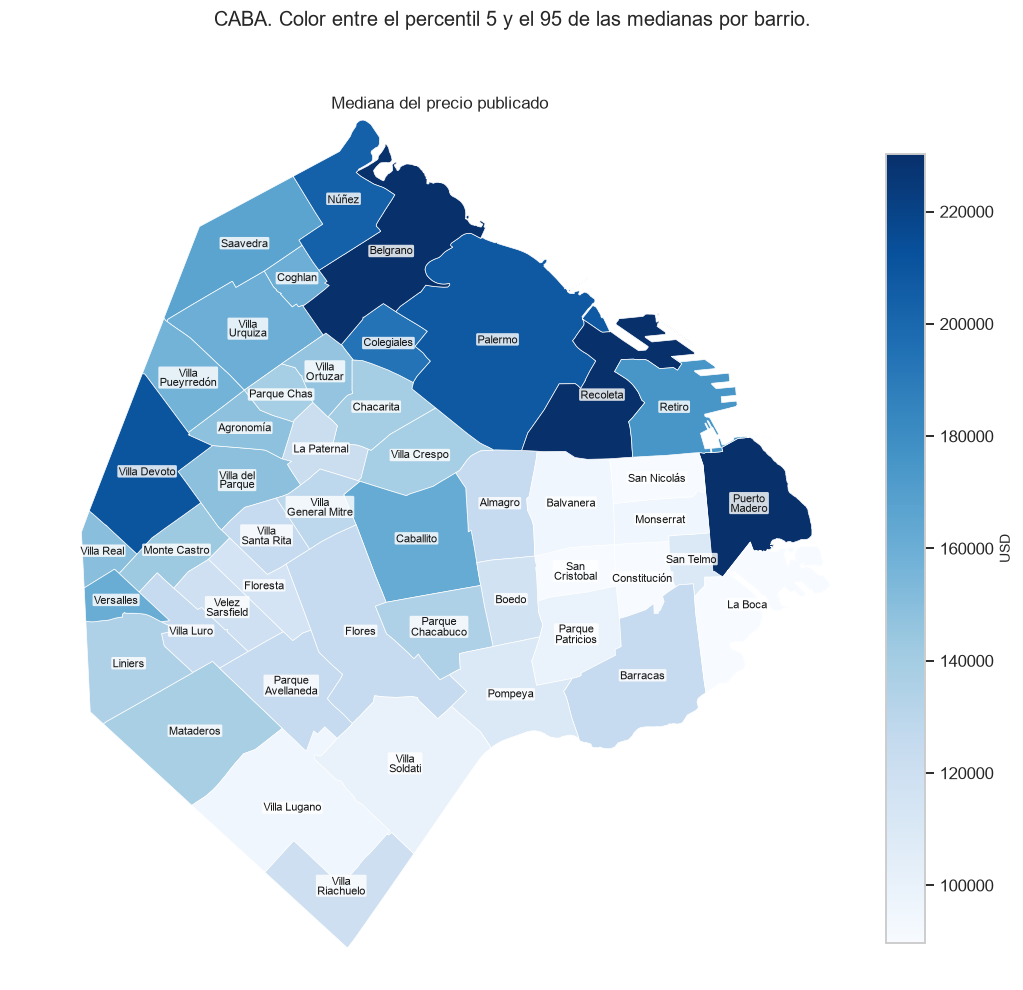

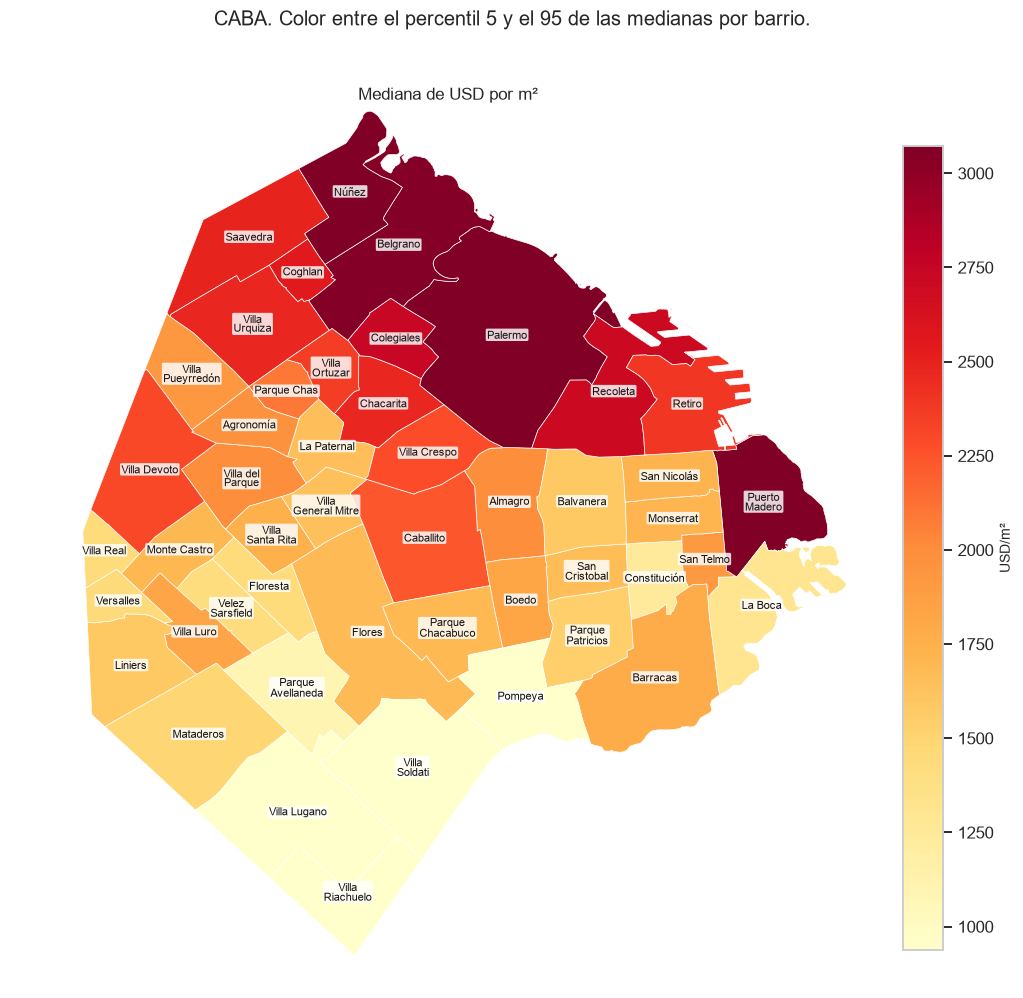

,barrio,n,mediana_usd,mediana_m2
0,Puerto Madero,1760,550.000,5.702
1,Palermo,11876,208.082,3.176
2,Núñez,3120,203.424,3.140
3,Belgrano,6554,231.020,3.051
4,Otro,30,323.500,3.013
5,Colegiales,1564,193.500,2.736
6,Recoleta,5605,230.000,2.700
7,Coghlan,645,160.000,2.556
8,Barrio Norte,1589,175.000,2.500
9,Saavedra,1458,166.500,2.493


In [17]:
caminos = []
for feature in barrios["features"]:
    for anillo in anillos(feature["geometry"]):
        caminos.append(Poligono(anillo))

claves_oficiales = {clave(feature["properties"]["BARRIO"]) for feature in barrios["features"]}
base_mapa = df.loc[en_caba & precio_ok & m2_ok].copy()
resumen_mapa = base_mapa.groupby("barrio_clave").agg(
    n=("precio_usd", "size"),
    mediana_usd=("precio_usd", "median"),
    mediana_m2=("precio_m2_usd", "median"),
)
nombres_barrio = df.groupby("barrio_clave")["barrio"].agg(lambda serie: serie.value_counts().index[0])

sin_poligono = sorted(set(df["barrio"]) - set(df.loc[df["barrio_clave"].isin(claves_oficiales), "barrio"]))
cobertura_mapa = df["barrio_clave"].isin(claves_oficiales).mean()
print(
    f"Avisos en un barrio con polígono oficial: {miles(100 * cobertura_mapa, 1)}%. "
    f"Sin polígono: {', '.join(sin_poligono)}."
)


def centroide(feature):
    anillo = max(
        (np.asarray(puntos) for puntos in anillos(feature["geometry"])),
        key=lambda puntos: len(puntos),
    )
    x, y = anillo[:, 0], anillo[:, 1]
    x2, y2 = np.roll(x, -1), np.roll(y, -1)
    cruz = x * y2 - x2 * y
    area = cruz.sum() / 2
    if abs(area) < 1e-14:
        return float(x.mean()), float(y.mean())
    return (
        float(((x + x2) * cruz).sum() / (6 * area)),
        float(((y + y2) * cruz).sum() / (6 * area)),
    )


def dibujar_barrios(ax, columna, titulo, cmap, etiqueta_color):
    valores = resumen_mapa[columna]
    norma = mcolors.Normalize(vmin=valores.quantile(0.05), vmax=valores.quantile(0.95))
    escala = plt.get_cmap(cmap)
    for feature in barrios["features"]:
        clave_barrio = clave(feature["properties"]["BARRIO"])
        fila = resumen_mapa.loc[clave_barrio] if clave_barrio in resumen_mapa.index else None
        if fila is None or fila["n"] < 30:
            color = "#ececec"
        else:
            color = escala(norma(fila[columna]))
        for anillo in anillos(feature["geometry"]):
            xs, ys = zip(*anillo)
            ax.fill(xs, ys, facecolor=color, edgecolor="white", linewidth=0.45, zorder=1)
    ax.set_xlim(-58.55, -58.325)
    ax.set_ylim(-34.712, -34.526)
    ax.set_aspect(1 / np.cos(np.radians(34.6)))
    ax.set_axis_off()
    ax.set_title(titulo)
    barra = plt.cm.ScalarMappable(norm=norma, cmap=escala)
    barra.set_array([])
    fig.colorbar(barra, ax=ax, fraction=0.046, pad=0.02, label=etiqueta_color)


def en_dos_lineas(nombre):
    partes = str(nombre).split()
    if len(partes) == 1 or len(nombre) <= 12:
        return str(nombre)
    corte = min(
        range(1, len(partes)),
        key=lambda i: abs(len(" ".join(partes[:i])) - len(" ".join(partes[i:]))),
    )
    return " ".join(partes[:corte]) + "\n" + " ".join(partes[corte:])


def poner_nombres(ax):
    puestos = []
    for feature in barrios["features"]:
        clave_barrio = clave(feature["properties"]["BARRIO"])
        cx, cy = centroide(feature)
        nombre = str(nombres_barrio.get(clave_barrio, feature["properties"]["BARRIO"]))
        texto = ax.text(
            cx,
            cy,
            en_dos_lineas(nombre),
            ha="center",
            va="center",
            fontsize=7.5,
            color="#141414",
            clip_on=False,
            zorder=5,
            linespacing=0.9,
            bbox={"boxstyle": "round,pad=0.12", "facecolor": "white", "edgecolor": "none", "alpha": 0.82},
        )
        puestos.append({"cx": cx, "cy": cy, "texto": texto})
    for _ in range(40):
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        cajas = [item["texto"].get_window_extent(renderer).padded(3.5) for item in puestos]
        se_movio = False
        for i, caja in enumerate(cajas):
            dx = dy = 0.0
            for j, otra in enumerate(cajas):
                if i == j:
                    continue
                ix = min(caja.x1, otra.x1) - max(caja.x0, otra.x0)
                iy = min(caja.y1, otra.y1) - max(caja.y0, otra.y0)
                if ix <= 0 or iy <= 0:
                    continue
                centro_i = ((caja.x0 + caja.x1) / 2, (caja.y0 + caja.y1) / 2)
                centro_j = ((otra.x0 + otra.x1) / 2, (otra.y0 + otra.y1) / 2)
                if ix < iy:
                    dx += (1 if centro_i[0] >= centro_j[0] else -1) * (ix * 0.55 + 0.8)
                else:
                    dy += (1 if centro_i[1] >= centro_j[1] else -1) * (iy * 0.55 + 0.8)
            origen = ax.transData.transform((puestos[i]["cx"], puestos[i]["cy"]))
            actual = ax.transData.transform(puestos[i]["texto"].get_position())
            dx += (origen[0] - actual[0]) * 0.08
            dy += (origen[1] - actual[1]) * 0.08
            dx = float(np.clip(dx, -12, 12))
            dy = float(np.clip(dy, -12, 12))
            if abs(dx) + abs(dy) < 0.45:
                continue
            se_movio = True
            nuevo = ax.transData.inverted().transform((actual[0] + dx, actual[1] + dy))
            puestos[i]["texto"].set_position(nuevo)
        if not se_movio:
            break


mapas = [
    ("mediana_usd", "Mediana del precio publicado", "Blues", "USD"),
    ("mediana_m2", "Mediana de USD por m²", "YlOrRd", "USD/m²"),
]
for columna, titulo, cmap, etiqueta in mapas:
    fig, ax = plt.subplots(figsize=(9.2, 9.6), constrained_layout=True)
    dibujar_barrios(ax, columna, titulo, cmap, etiqueta)
    poner_nombres(ax)
    fig.suptitle("CABA. Color entre el percentil 5 y el 95 de las medianas por barrio.", fontsize=13)
    plt.show()

tabla_barrios = resumen_mapa.join(nombres_barrio.rename("barrio"))
tabla_barrios = tabla_barrios.sort_values("mediana_m2", ascending=False)
vista_barrios = tabla_barrios[["barrio", "n", "mediana_usd", "mediana_m2"]].copy()
vista_barrios["mediana_usd"] = tabla_barrios["mediana_usd"].map(lambda valor: miles(valor, 0))
vista_barrios["mediana_m2"] = tabla_barrios["mediana_m2"].map(lambda valor: miles(valor, 0))
display(vista_barrios.reset_index(drop=True))


## Subte y precio

La red y las estaciones son las de Subterráneos de Buenos Aires, publicadas en los datos
abiertos de la Ciudad. Como cada aviso está clavado en una grilla de ~1 km, armo el mapa
así: en cada celda de esa grilla calculo la mediana de USD/m² (si hay al menos 20 avisos),
interpolo esas celdas, suavizo apenas el resultado y lo recorto al polígono de la ciudad.
Encima dibujo las líneas y las estaciones.

Eso muestra dónde es caro el metro cuadrado y por dónde pasa el subte. No alcanza para decir
que la estación sube el precio: las líneas del norte cruzan los barrios caros. Por eso, además
del Spearman general, calculo el Spearman **dentro de cada barrio**. Si el general es fuerte
y el de adentro del barrio es débil, la foto es composición de barrios, no proximidad.


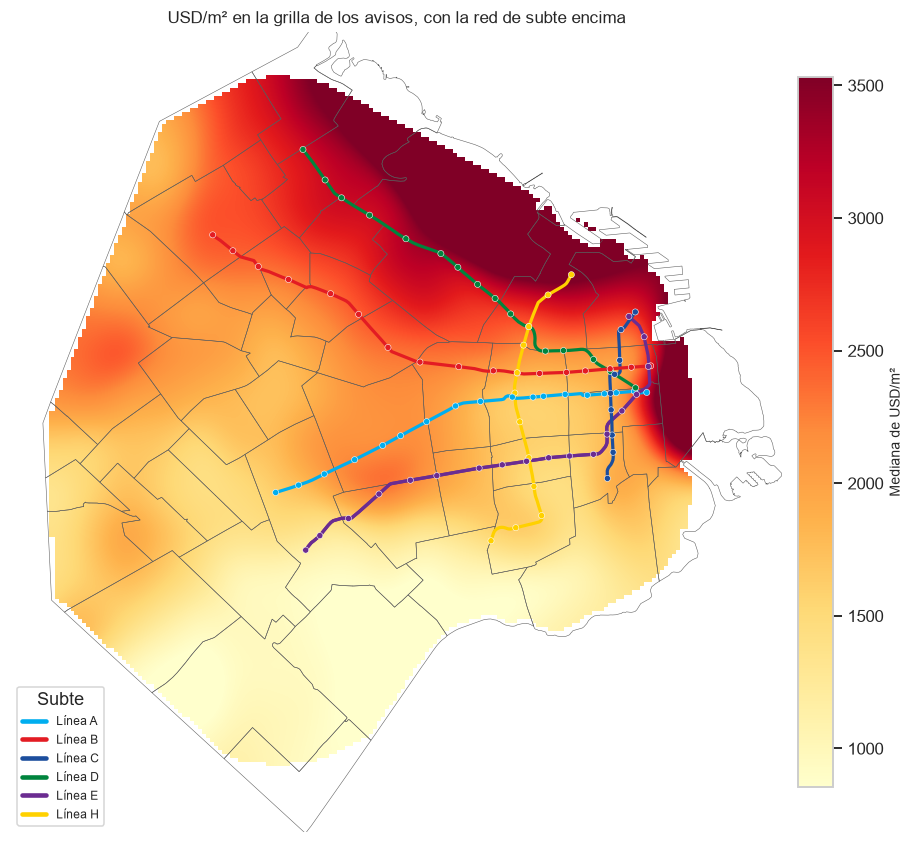

Celdas de 0,01° con al menos 20 avisos: 179.


In [18]:
celdas = (
    base_mapa.assign(lat_celda=lambda datos: datos["latitud"].round(2), lon_celda=lambda datos: datos["longitud"].round(2))
    .groupby(["lat_celda", "lon_celda"], as_index=False)
    .agg(n=("precio_m2_usd", "size"), mediana_m2=("precio_m2_usd", "median"), mediana_usd=("precio_usd", "median"))
)
celdas_uso = celdas[celdas["n"] >= 20].copy()
distancia_celda, _ = distancia_minima(celdas_uso["lat_celda"], celdas_uso["lon_celda"])
celdas_uso["distancia_subte_km"] = distancia_celda

lon_grid = np.linspace(-58.53, -58.35, 170)
lat_grid = np.linspace(-34.70, -34.53, 190)
lon_malla, lat_malla = np.meshgrid(lon_grid, lat_grid)
raster = griddata(
    celdas_uso[["lon_celda", "lat_celda"]].to_numpy(),
    celdas_uso["mediana_m2"].to_numpy(),
    (lon_malla, lat_malla),
    method="linear",
)
mascara = np.isfinite(raster)
numerador = gaussian_filter(np.where(mascara, raster, 0.0), sigma=4)
denominador = gaussian_filter(mascara.astype(float), sigma=4)
calor = np.divide(numerador, denominador, out=np.full_like(numerador, np.nan), where=denominador >= 0.35)

puntos = np.column_stack([lon_malla.ravel(), lat_malla.ravel()])
adentro = np.zeros(len(puntos), dtype=bool)
for camino in caminos:
    adentro |= camino.contains_points(puntos)
calor[~adentro.reshape(calor.shape)] = np.nan

vmin = np.nanpercentile(celdas_uso["mediana_m2"], 5)
vmax = np.nanpercentile(celdas_uso["mediana_m2"], 95)

fig, ax = plt.subplots(figsize=(8.2, 8.4), constrained_layout=True)
for feature in barrios["features"]:
    for anillo in anillos(feature["geometry"]):
        xs, ys = zip(*anillo)
        ax.plot(xs, ys, color="#5c5c5c", lw=0.35, zorder=2)
imagen = ax.imshow(
    calor,
    origin="lower",
    extent=[lon_grid[0], lon_grid[-1], lat_grid[0], lat_grid[-1]],
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    zorder=1,
    interpolation="bilinear",
)
for feature in red["features"]:
    coords = feature["geometry"]["coordinates"]
    letra = feature["properties"]["nombre"].replace("Linea ", "")
    ax.plot(
        [punto[0] for punto in coords],
        [punto[1] for punto in coords],
        color=COLORES_LINEA.get(letra, "#222222"),
        lw=2.1,
        solid_capstyle="round",
        zorder=3,
    )
ax.scatter(
    estaciones["lon"],
    estaciones["lat"],
    s=16,
    c=estaciones["linea"].map(COLORES_LINEA),
    edgecolor="white",
    linewidth=0.35,
    zorder=4,
)
ax.set_xlim(-58.54, -58.335)
ax.set_ylim(-34.705, -34.53)
ax.set_aspect(1 / np.cos(np.radians(34.6)))
ax.set_axis_off()
ax.legend(
    handles=[Line2D([0], [0], color=color, lw=3, label=f"Línea {linea}") for linea, color in COLORES_LINEA.items()],
    loc="lower left",
    frameon=True,
    fontsize=8,
    title="Subte",
)
fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.02, label="Mediana de USD/m²")
ax.set_title("USD/m² en la grilla de los avisos, con la red de subte encima")
plt.show()
print(f"Celdas de 0,01° con al menos 20 avisos: {len(celdas_uso)}.")


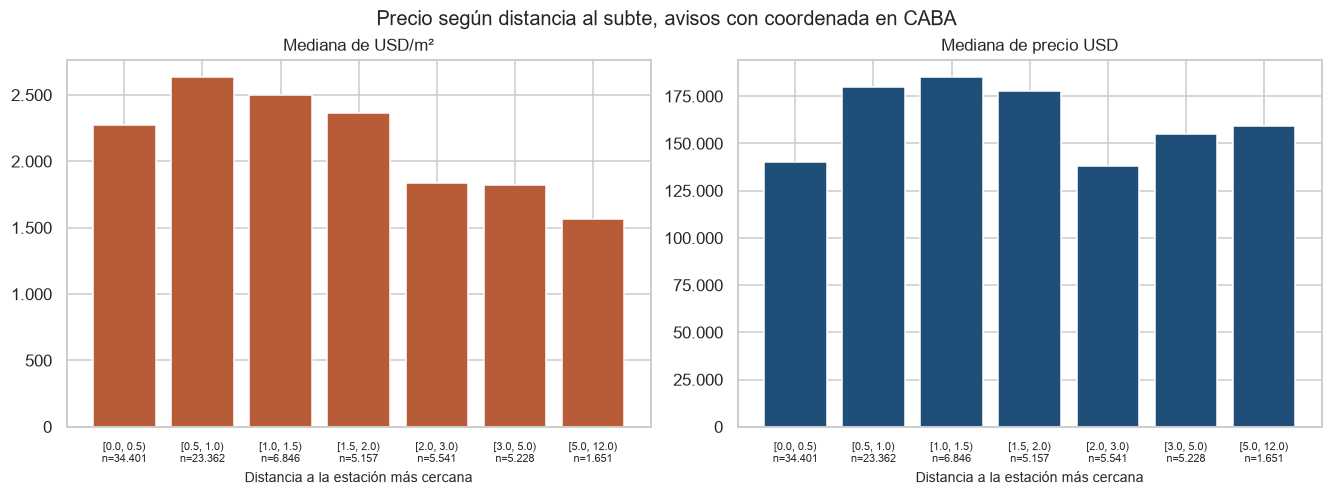

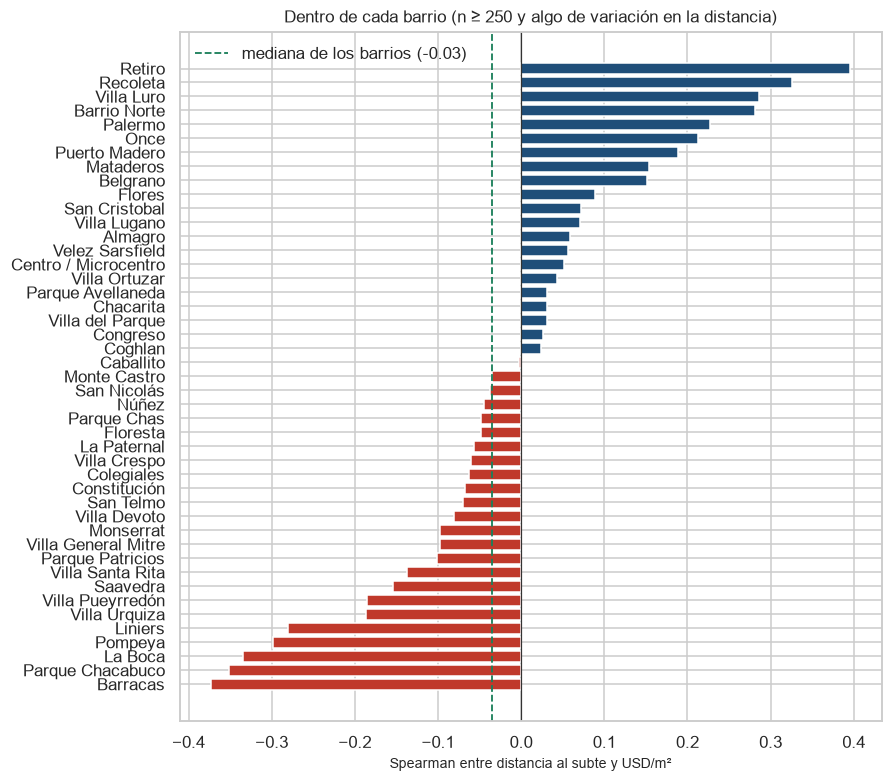

**Estaciones con la mediana de USD/m² más alta y más baja**, avisos a 1,2 km o menos y al menos 80 avisos.

,linea_subte_cercana,estacion_subte_cercana,n,mediana_m2,mediana_usd
0,A,Plaza De Mayo,1153,5.192,474.000
1,D,Palermo,2247,3.415,180.000
2,D,R.Scalabrini Ortiz,2677,3.308,289.000
3,D,Ministro Carranza - Miguel Abuelo,1838,3.303,213.445
4,D,Olleros,1858,3.093,250.000
5,D,Juramento,2698,3.045,229.000
6,D,Jose Hernandez,2152,3.022,203.696
7,D,Plaza Italia,1119,2.982,195.000
8,A,San Pedrito,973,1.547,98.000
9,E,Entre Rios - Rodolfo Walsh,1148,1.541,85.000


Spearman distancia–USD/m² entre avisos: **-0.04**. Entre celdas de la grilla: **-0.38**. Mediana de los Spearman dentro del barrio: **-0.03**.

In [19]:
muestra = df.loc[m2_ok & df["distancia_subte_km"].notna(), ["distancia_subte_km", "precio_m2_usd", "precio_usd", "barrio"]].copy()
cortes = [0, 0.5, 1, 1.5, 2, 3, 5, 12]
muestra["tramo"] = pd.cut(muestra["distancia_subte_km"], cortes, right=False)
tramos = muestra.groupby("tramo", observed=True).agg(
    n=("precio_m2_usd", "size"),
    mediana_m2=("precio_m2_usd", "median"),
    mediana_usd=("precio_usd", "median"),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
ejes_x = np.arange(len(tramos))
axes[0].bar(ejes_x, tramos["mediana_m2"], color="#b85c38")
axes[1].bar(ejes_x, tramos["mediana_usd"], color=COLOR)
for ax, titulo in zip(axes, ["Mediana de USD/m²", "Mediana de precio USD"]):
    ax.set_xticks(ejes_x)
    ax.set_xticklabels([f"{intervalo}\nn={miles(n)}" for intervalo, n in zip(tramos.index.astype(str), tramos["n"])], fontsize=7)
    ax.set_title(titulo)
    ax.yaxis.set_major_formatter(eje_miles(0))
    ax.set_xlabel("Distancia a la estación más cercana")
fig.suptitle("Precio según distancia al subte, avisos con coordenada en CABA", fontsize=13)
plt.show()

rho_avisos = muestra["distancia_subte_km"].corr(muestra["precio_m2_usd"], method="spearman")
rho_celdas = celdas_uso["distancia_subte_km"].corr(celdas_uso["mediana_m2"], method="spearman")

dentro = []
for barrio, grupo in muestra.groupby("barrio"):
    if len(grupo) < 250 or grupo["distancia_subte_km"].std() < 0.15:
        continue
    dentro.append(
        {
            "barrio": barrio,
            "n": len(grupo),
            "rho": grupo["distancia_subte_km"].corr(grupo["precio_m2_usd"], method="spearman"),
            "distancia_mediana": grupo["distancia_subte_km"].median(),
        }
    )
dentro = pd.DataFrame(dentro).sort_values("rho")
fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
ax.barh(dentro["barrio"], dentro["rho"], color=[ACENTO if valor < 0 else COLOR for valor in dentro["rho"]])
ax.axvline(0, color="#333333", lw=0.8)
ax.axvline(dentro["rho"].median(), color=VERDE, ls="--", lw=1.2, label=f"mediana de los barrios ({dentro['rho'].median():.2f})")
ax.set_xlabel("Spearman entre distancia al subte y USD/m²")
ax.set_title("Dentro de cada barrio (n ≥ 250 y algo de variación en la distancia)")
ax.legend(frameon=False)
plt.show()

cerca = df.loc[df["distancia_subte_km"].le(1.2) & m2_ok & precio_ok]
por_estacion = (
    cerca.groupby(["linea_subte_cercana", "estacion_subte_cercana"], as_index=False)
    .agg(n=("precio_m2_usd", "size"), mediana_m2=("precio_m2_usd", "median"), mediana_usd=("precio_usd", "median"))
)
por_estacion = por_estacion[por_estacion["n"] >= 80].sort_values("mediana_m2", ascending=False)
vista_estacion = pd.concat([por_estacion.head(8), por_estacion.tail(8)], ignore_index=True)
vista_estacion["mediana_m2"] = vista_estacion["mediana_m2"].map(lambda valor: miles(valor, 0))
vista_estacion["mediana_usd"] = vista_estacion["mediana_usd"].map(lambda valor: miles(valor, 0))
display(Markdown("**Estaciones con la mediana de USD/m² más alta y más baja**, avisos a 1,2 km o menos y al menos 80 avisos."))
display(vista_estacion.reset_index(drop=True))
display(
    Markdown(
        f"Spearman distancia–USD/m² entre avisos: **{rho_avisos:.2f}**. "
        f"Entre celdas de la grilla: **{rho_celdas:.2f}**. "
        f"Mediana de los Spearman dentro del barrio: **{dentro['rho'].median():.2f}**."
    )
)


## Qué me llevo para un modelo de precio

La mediana del aviso en rango es 156.900 USD y la media 248.986. La media cruda
(261.261) no sirve: el máximo publicado es 940.000.000. Conviene modelar el precio
en log, o mirar el error en porcentaje, porque la cola derecha es larga aun después
de tirar esos imposibles.

Lo que más ordena el precio total es el tamaño. Spearman aproximado, dentro del rango:
superficie total 0,78, cubierta 0,76, baños 0,65, ambientes 0,60, dormitorios 0,55.

El barrio mueve el valor del metro, no solo el ticket. La mediana de USD/m² va de
5.702 en Puerto Madero a alrededor de 3.100 en Palermo, Núñez y Belgrano, y baja a
722 en Villa Soldati y 799 en Pompeya. Villa Devoto tiene un ticket alto y un metro
más moderado: ahí el precio total está mezclado con casas grandes.

De las menciones en el texto, amenities y pileta separan el USD/m²
(la mediana pasa de unos 2.100 a más de 3.100). Parrilla acompaña
menos. Jardín casi no mueve el metro (2.297 contra 2.507) pero sí el precio total
(150.000 contra 265.000): está proxyando casa y superficie.
Apto crédito es la asociación negativa más clara con el precio total (Spearman cerca de −0,22): el flag
aparece en los avisos más baratos. Antigüedad también empuja levemente hacia abajo.
Las fotos del aviso correlacionan con el precio, pero miden cómo se armó la publicación.

En el mapa, la línea D atraviesa la mancha cara del norte y las colas de las líneas
A, E y H caen en la mancha barata del sur y el oeste. Eso no es un efecto de la
estación. Entre avisos, el Spearman entre distancia al subte y USD/m² es −0,04.
Entre celdas de la grilla es −0,38: aparece la geografía de la ciudad. Dentro de
cada barrio la mediana de ese Spearman es −0,03, con signos distintos: en Retiro,
Palermo o Belgrano alejarse de la estación no baja el metro, y en Barracas, La Boca
o Liniers sí. La coordenada, además, tiene error de alrededor de un kilómetro.
La estación más cara de la tabla es Plaza de Mayo porque ahí caen los avisos de
Puerto Madero, que no tienen una estación propia.

Antes de modelar dejaría afuera los valores de la tabla de rangos, no rellenaría
cocheras ni toilettes con cero, y no usaría `precio_m2_usd` como predictor del precio (*data leakage*).